# Custom Task Performance Analysis

Copy of `02_task_performance_analysis`, trimmed to the setup needed for Plot 1 onward.

In [1]:
# autoreload
%load_ext autoreload
%autoreload 2

# Stashes each saved PDF's title/axis labels in its own metadata (no
# per-plot wiring needed) -- read back by the figure report's Prism cards.
import compass_labyrinth.figure_labels

# Load project

In [2]:
from pathlib import Path
import pandas as pd
from compass_labyrinth import load_project


project_path = Path(r'D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis')

config, cohort_metadata = load_project(project_path=project_path)
config

# Mouse metadata joined onto every datasheet table -- set up here, before
# the first figure (Exclusion Criteria) records anything.
import compass_labyrinth.source_data as source_data

_meta = cohort_metadata[["session", "mouseid", "sex", "genotype"]].rename(
    columns={"mouseid": "mouse_id", "genotype": "group_label"}
)
source_data.configure(_meta)


# Import Combined DLC CSV

In [3]:
df_all_csv = pd.read_csv(project_path / "csvs" / "combined" / "preprocessed_combined_file.csv")
df_all_csv

,x,y,grid_number,likelihood,s_no,region,session,genotype,sex,node_type,velocity
0,843.278259,755.115112,1,0.773517,1869,entry_zone,1,E4,Female,Entry Zone,0.000000
1,848.428711,760.598816,1,0.645074,1886,entry_zone,1,E4,Female,Entry Zone,37.615874
2,845.134521,745.213501,1,0.789584,1892,entry_zone,1,E4,Female,Entry Zone,78.670134
3,850.454285,737.817017,1,0.960428,1893,entry_zone,1,E4,Female,Entry Zone,45.554325
4,850.547119,737.732239,1,0.932537,1894,entry_zone,1,E4,Female,Entry Zone,0.628600
...,...,...,...,...,...,...,...,...,...,...,...
1278343,855.048035,757.522705,1,0.998800,222293,entry_zone,22,E4,Female,Entry Zone,65.143538
1278344,855.437622,763.145325,1,0.998787,222294,entry_zone,22,E4,Female,Entry Zone,28.180503
1278345,846.409729,791.627319,0,0.935974,222295,entry_zone,22,E4,Female,Entry Zone,149.392676
1278346,845.499573,788.181519,0,0.989881,222296,entry_zone,22,E4,Female,Entry Zone,17.819882


# Create Time-Binned Dictionary

This workflow bins data from each session into defined intervals and calculates normalized region occupancy for each genotype. Each pivot table summarizes the proportion of time spent in each region across all sessions for a given bin.

### Recommended Use:
1. Ensure `df_all_csv` contains 'Session', 'Genotype', and 'Region' columns.
2. Set `LOWER_LIMIT` and `UPPER_LIMIT` to define the full range of timepoints to analyze.
3. Set `BIN_SIZE` (used as `difference`) to determine the duration of each bin (e.g., 10000).
4. Provide `region_lengths` as a dictionary mapping region names to their total grid lengths.
5. The function returns a dictionary of pivot tables (one per genotype), useful for heatmap plotting.

Let's generate pivot tables for each genotype and time bin:

In [4]:
from compass_labyrinth.behavior.behavior_metrics.task_performance_analysis import generate_region_heatmap_pivots


pivot_dict = generate_region_heatmap_pivots(
    df=df_all_csv,
    lower_lim=0,        # Start of time window
    upper_lim=80000,    # End of time window
    difference=10000,   # Bin width in timepoints
    region_columns=["entry_zone", "reward_path", "overshoot", "target_zone"],
)
pivot_dict

{'E4': [session            1         2    3    4    5    6    7    8    9         10  \
  region                                                                         
  entry_zone   0.442039  0.425453  NaN  NaN  NaN  NaN  NaN  NaN  NaN  0.073475   
  overshoot    0.151347  0.003314  NaN  NaN  NaN  NaN  NaN  NaN  NaN   0.24351   
  reward_path  0.205097  0.199291  NaN  NaN  NaN  NaN  NaN  NaN  NaN   0.25103   
  target_zone  0.201518  0.371942  NaN  NaN  NaN  NaN  NaN  NaN  NaN  0.431985   
  
  session      ...   12   13   14   15   16   17   18   19   21        22  
  region       ...                                                         
  entry_zone   ...  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  0.208448  
  overshoot    ...  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  0.157544  
  reward_path  ...  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  0.127883  
  target_zone  ...  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  0.506125  
  
  [4 rows x 21 columns],
  session      

# Exclusion Criteria

This workflow quantifies target zone engagement across bouts and sessions, plots the relationship between target usage and session duration, and interactively excludes low-performing sessions based on user-defined thresholds.

### Recommended Use:
1. Ensure `df_all_csv` contains 'Session', 'Genotype', 'Grid.Number', and 'Bout_Index' columns.
2. Run `compute_frames_per_session()` to get the number of frames per session.
3. Use `compute_target_zone_usage()` to calculate per-bout usage for a specified region; set `region` and `difference` accordingly.
4. Summarize target usage at the session level using `summarize_target_usage()` with `mouseinfo` to add sex/genotype metadata.
5. Visualize the relationship between number of frames and target usage using `plot_target_usage_vs_frames()`.
6. Call `exclude_low_performing_sessions()` to interactively remove sessions below usage and duration thresholds.

Example Workflow:


Excluding 0 session(s): []
Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\exclusion_criteria\target_usage_vs_frames.png


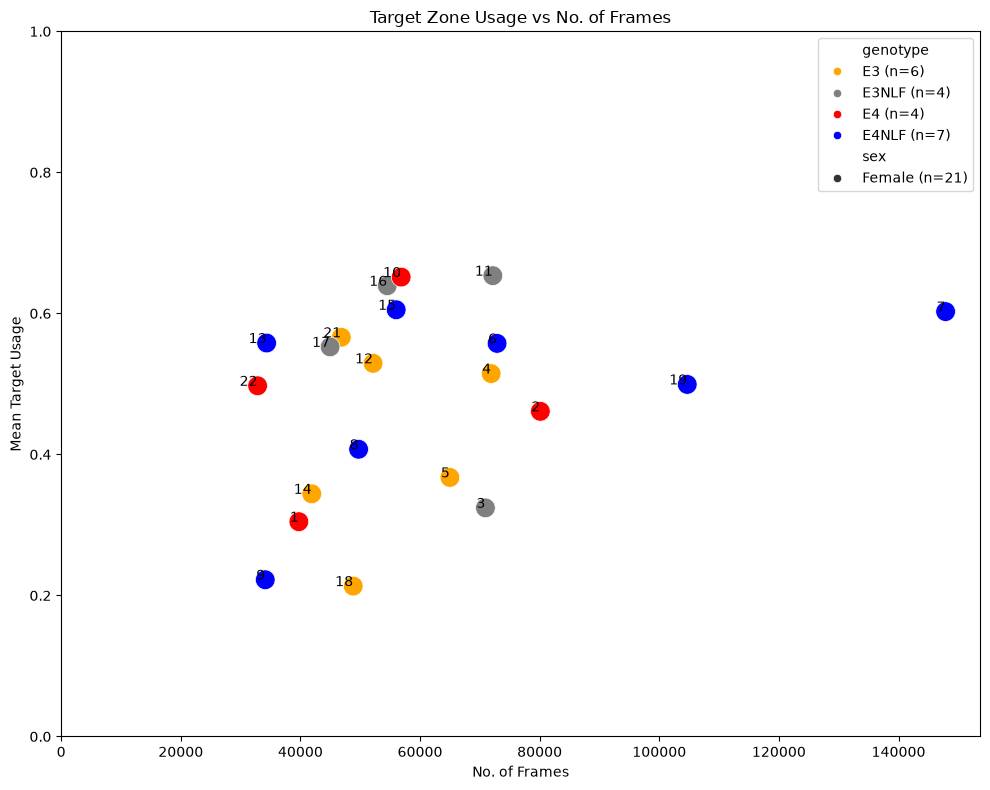

Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\exclusion_criteria\target_usage_vs_frames_exclusions.png


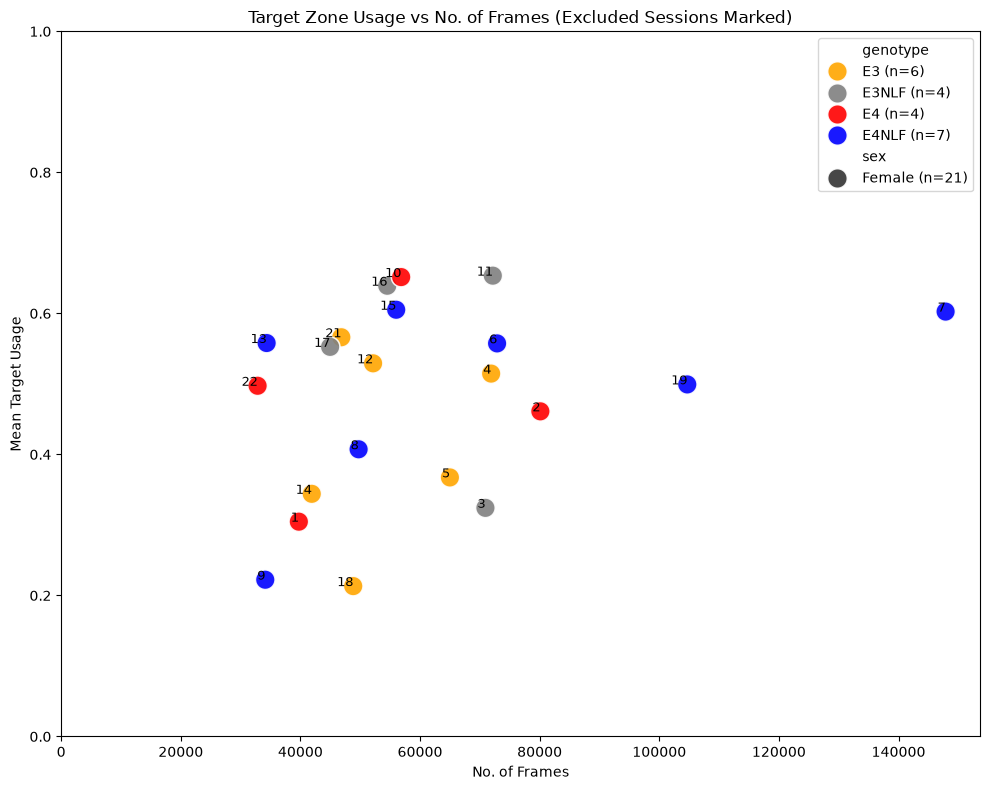

In [5]:
from compass_labyrinth.behavior.behavior_metrics.task_performance_analysis import (
    compute_frames_per_session,
    compute_target_zone_usage,
    summarize_target_usage,
    plot_target_usage_vs_frames,
    exclude_low_performing_sessions,
    plot_target_usage_with_exclusions
)


# Set these values
BIN_SIZE = 10000               # BASED ON THE TIME-BINNED DICTIONARY
REGION = "target_zone"         # Region to evaluate usage

# Steps 1-3: per-session target-zone usage vs. session length (raw genotypes)
frames_df = compute_frames_per_session(df=df_all_csv)
region_target = compute_target_zone_usage(
    df=df_all_csv,
    pivot_dict=pivot_dict,
    region=REGION,
    difference=BIN_SIZE,
)
region_summary = summarize_target_usage(
    region_target=region_target,
    frames_df=frames_df,
    cohort_metadata=cohort_metadata,
)

# Step 4: drop low-performing sessions -- once; every later cell uses the filtered df_all_csv
df_all_csv = exclude_low_performing_sessions(
    df=df_all_csv,
    summary_df=region_summary,
    usage_threshold=0.4,
    min_frames=30000,
)
sessions_to_exclude = region_summary.loc[
    ~region_summary["session"].isin(df_all_csv["session"])
]["session"].tolist()

# Step 5: before/after figures -- one each, on the raw genotypes (exclusion
# is per session, so a genotype comparison adds nothing here)
plot_target_usage_vs_frames(
    config=config,
    figures_dirname="figures/task_performance/exclusion_criteria",
    summary_df=region_summary,
)
plot_target_usage_with_exclusions(
    config=config,
    figures_dirname="figures/task_performance/exclusion_criteria",
    summary_df=region_summary,
    sessions_to_exclude=sessions_to_exclude,
)

### Subset the Time-Binned Dictionary based on Valid Sessions

In [6]:
from compass_labyrinth.behavior.behavior_metrics.task_performance_analysis import subset_pivot_dict_sessions


pivot_dict = subset_pivot_dict_sessions(pivot_dict, df_all_csv)
pivot_dict

{'E4': [session            1         2         10        22
  region                                             
  entry_zone   0.442039  0.425453  0.073475  0.208448
  overshoot    0.151347  0.003314   0.24351  0.157544
  reward_path  0.205097  0.199291   0.25103  0.127883
  target_zone  0.201518  0.371942  0.431985  0.506125,
  session            1         2         10        22
  region                                             
  entry_zone   0.458158  0.416682  0.062549  0.169191
  overshoot    0.155686  0.070149  0.040345  0.119465
  reward_path  0.166121  0.161593  0.163983  0.115421
  target_zone  0.220036  0.351576  0.733123  0.595922,
  session            1         2         10        22
  region                                             
  entry_zone   0.289872  0.130897  0.075535  0.127195
  overshoot    0.145758  0.195931   0.10869  0.168696
  reward_path  0.129563  0.098378  0.098814  0.102118
  target_zone  0.434808  0.574794  0.716961  0.601991,
  session          

## Define Custom Zones and Genotypes

`ZONES` defines each zone once, by grid cell number (0-99) -- see `media/new_maze_layout_v2.svg` for the cell layout. `ZONE_SETS` then groups zone names into the combinations used below (a zone can belong to more than one set). Every plot cell just picks a set by name (e.g. `ZONE_NAMES = ZONE_SETS["5_column"]`) instead of redefining cell numbers itself. Add a new zone to `ZONES` or a new combination to `ZONE_SETS` to make it available everywhere.

`GENOTYPE_SETS` is `set_name -> {label: [raw genotype strings]}`. A label mapping to one raw genotype (e.g. `"pair"`) keeps genotypes separate; a label mapping to several (e.g. `"wt_nlf"`'s `"WT": ["E3", "E4"]`) pools them into one group. Both cases are used identically -- there's no separate "raw" vs "pooled" mechanism:

```python
GENOTYPE_SET = "wt_nlf"                                   # or "pair", "all", "apoe_pair", ...
GENOTYPES = list(GENOTYPE_SETS[GENOTYPE_SET].keys())       # ["WT", "NLF"]
df_geno = build_genotype_groups(df_all_csv, GENOTYPE_SET)  # genotype column relabeled/filtered
```

`build_zone_pivot(zone_names, df=df_geno)` then relabels `df_geno` by the chosen zones and builds a matching pivot dict. Sections that are not zone-based (bout success, deviation, backtracking) skip `build_zone_pivot()` and use `df_geno` directly, but still get their genotype scoping from `build_genotype_groups()`.

In [7]:
from compass_labyrinth.behavior.behavior_metrics.task_performance_analysis import (
    generate_region_heatmap_pivots,
    generate_region_heatmap_pivots_by_percentage,
    subset_pivot_dict_sessions,
    get_max_session_row_bracket,
    build_zone_pivot as _build_zone_pivot_pkg,
    build_zone_pivot_by_percentage as _build_zone_pivot_by_percentage_pkg,
)
from compass_labyrinth.utils import build_genotype_groups as _build_genotype_groups_pkg


LOWER_LIMIT = 0
BIN_SIZE = 5000
UPPER_LIMIT = get_max_session_row_bracket(df_all_csv)

# Maze zones, zone groupings, genotype groupings, and which genotype groupings
# to generate/offer as a report "Comparison" -- all read from config.yaml now
# (zones/zone_sets/genotype_sets/comparisons), so this notebook, 05b, and the
# figure report share one definition. A different project with a different
# maze layout or genotype labels only needs its own config.yaml, not edits here.
ZONES = config["zones"]
ZONE_SETS = config["zone_sets"]
GENOTYPE_SETS = config["genotype_sets"]
COMPARISONS = config["comparisons"]


def build_zone_pivot(zone_names, df=None, lower_lim=LOWER_LIMIT, upper_lim=UPPER_LIMIT, difference=BIN_SIZE):
    """Thin wrapper preserving this notebook's call signature -- the actual
    (cached) work happens in compass_labyrinth's build_zone_pivot(), which
    takes ZONES/the dataframe as explicit arguments instead of closing over
    notebook globals, so it has a stable, importable location for joblib to
    cache against (an inline notebook function's cache location is tied to
    this kernel's temp file path and wouldn't survive a kernel restart).
    """
    if df is None:
        df = df_all_csv
    return _build_zone_pivot_pkg(zone_names, ZONES, df, lower_lim, upper_lim, difference)


def build_zone_pivot_by_percentage(zone_names, df=None, n_bins=5):
    """Thin wrapper -- see build_zone_pivot() above."""
    if df is None:
        df = df_all_csv
    return _build_zone_pivot_by_percentage_pkg(zone_names, ZONES, df, n_bins)


def build_genotype_groups(df, set_name):
    """Thin wrapper -- see build_zone_pivot() above."""
    return _build_genotype_groups_pkg(df, set_name, GENOTYPE_SETS)



# --- Cache expensive, deterministic computations in the project's own folder ---
# (not this git repo, and specific to this dataset) so repeated notebook runs
# -- including after a kernel restart -- skip recomputation until an actual
# input (the dataframe, genotype set, zone set, or bin size) changes. See
# compass_labyrinth.caching.get_memory().
from compass_labyrinth.caching import get_memory
from compass_labyrinth.behavior.behavior_metrics import task_performance_analysis as _tpa


memory = get_memory(config)
# Only steps that cost far more to compute than to check are cached: a cache
# hit still has to hash the whole (1.28M-row) input dataframe, ~5 s.
_build_zone_pivot_pkg = memory.cache(_build_zone_pivot_pkg)
_build_zone_pivot_by_percentage_pkg = memory.cache(_build_zone_pivot_by_percentage_pkg)
# Patched on the package itself, not just this cell's local name -- later
# cells re-import these via `from ...task_performance_analysis import ...`,
# which would otherwise rebind the plain (uncached) function again.
_tpa.compute_zone_occupancy_velocity = memory.cache(_tpa.compute_zone_occupancy_velocity)
_tpa.compute_zone_occupancy_velocity_by_percentage = memory.cache(_tpa.compute_zone_occupancy_velocity_by_percentage)


# Plot 1: Heatmap Representations

Spatial heatmap of time spent in each maze zone (zones excluding the entry corridor) across time bins, with every genotype group overlaid in one figure for direct comparison. Pick a comparison below: the 4 individual genotypes, pooled WT vs. NLF, or pooled APOE3 vs. APOE4.

**How the values are normalized:** for each zone, raw frame counts are first divided by that zone's cell count (so a 36-cell zone isn't favored over a 6-cell zone just for being bigger) -- this gives a density (frames per cell). Those densities are then rescaled so they sum to 100%, but **only across the zones in `ZONE_NAMES`** for that plot, not the whole maze.


Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot1_heatmap\region_heatmaps_wt_nlf_except_entry.pdf


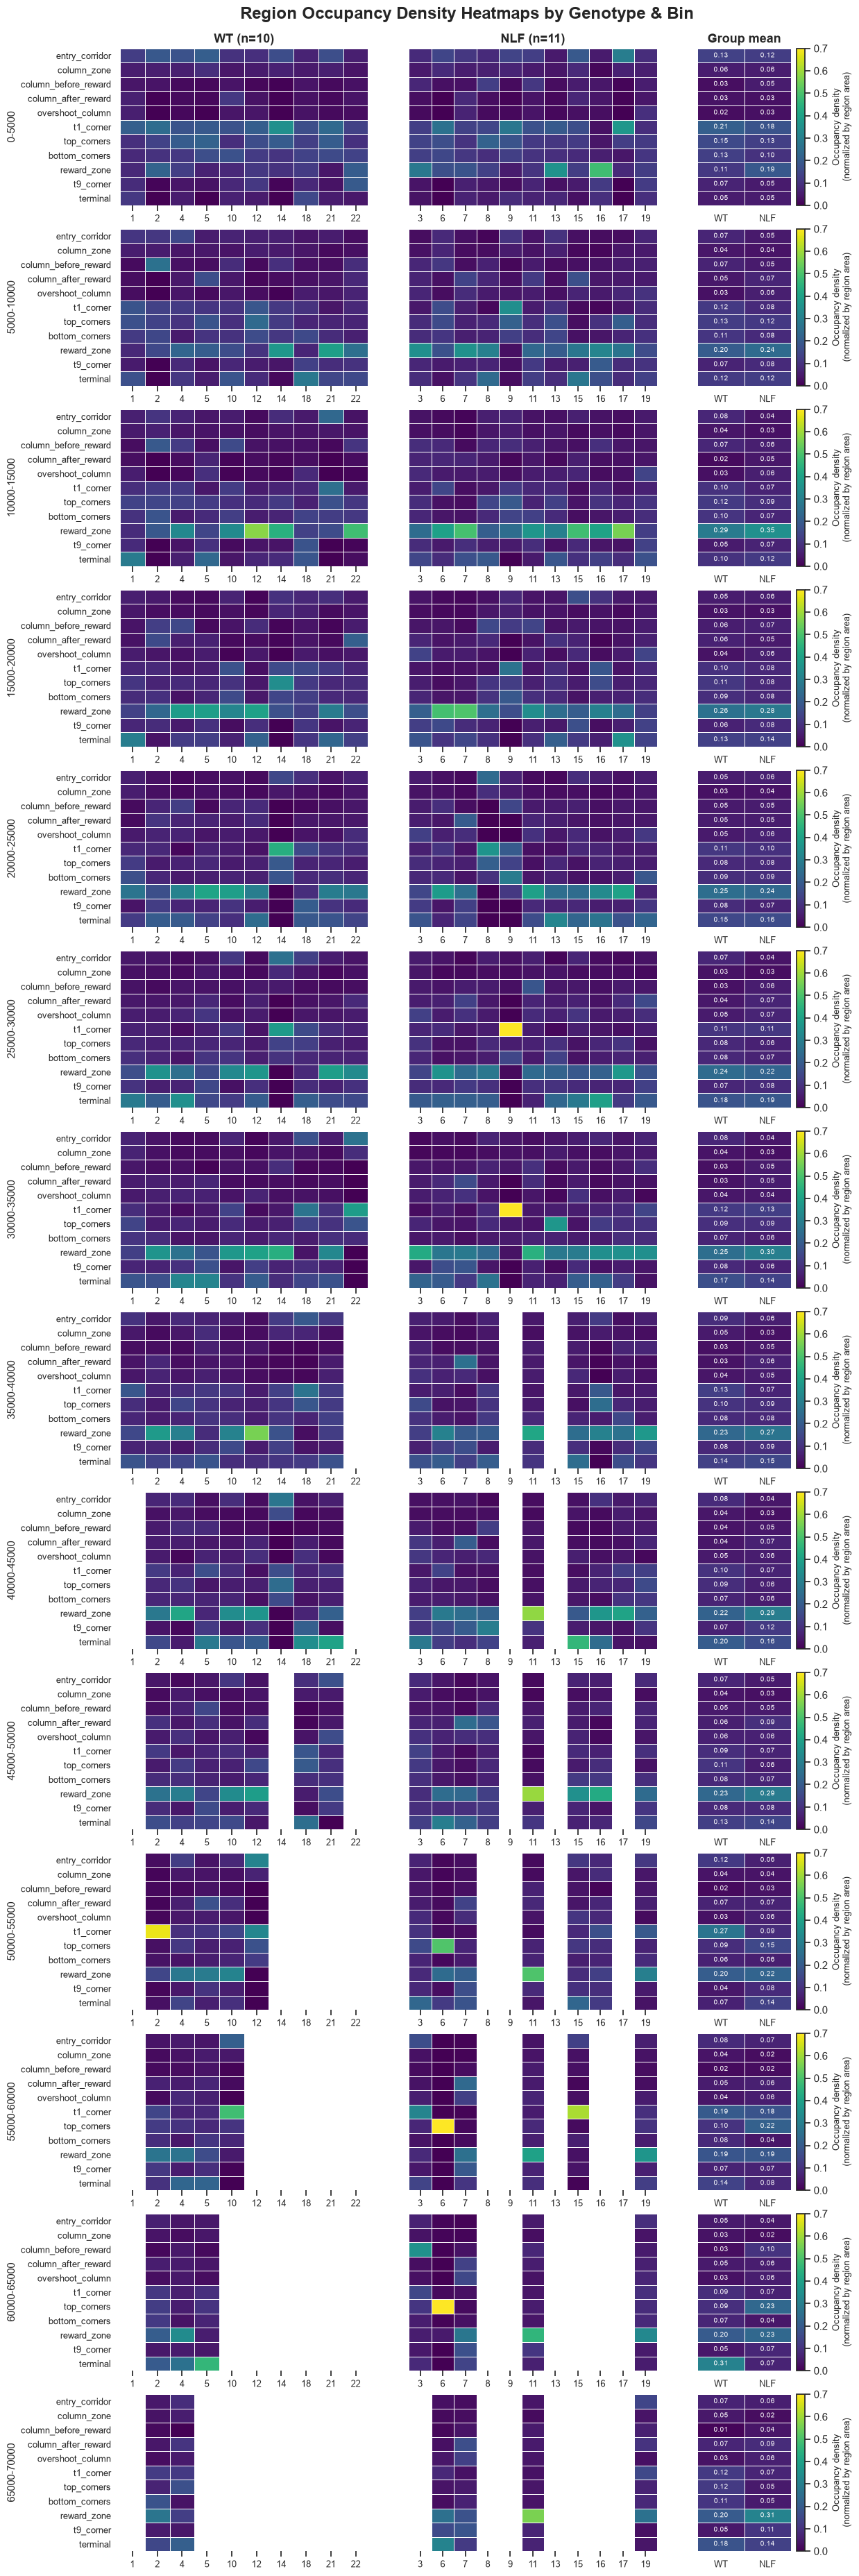

Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot1_heatmap\region_heatmaps_apoe_pair_except_entry.pdf
Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot1_heatmap\region_heatmaps_all_except_entry.pdf


In [8]:
from compass_labyrinth.behavior.behavior_metrics.task_performance_analysis import plot_region_heatmaps_all_genotypes

# Zone sets to plot (names from config.yaml zone_sets) -- add/remove names; one figure per comparison x set
ZONE_SET = ["except_entry"]
VMAX = 0.7  # max range on colorbar -- real data for original_4/wt_nlf reaches 1.0 (single-zone bins)
PLOT1_UPPER_LIMIT = 70000  # last frame shown (pivots themselves still span UPPER_LIMIT)

FIRST = (COMPARISONS[0], ZONE_SET[0])
for zone_set in ZONE_SET:
    ZONE_NAMES = ZONE_SETS[zone_set]
    for GENOTYPE_SET in COMPARISONS:
        df_geno = build_genotype_groups(df_all_csv, GENOTYPE_SET)
        df_zones, pivot_dict_zones = build_zone_pivot(ZONE_NAMES, df=df_geno)

        plot_region_heatmaps_all_genotypes(
            config=config,
            show_fig=(GENOTYPE_SET, zone_set) == FIRST,  # display only the first comparison x zone set; all are saved
            figures_dirname="figures/task_performance/plot1_heatmap",
            pivot_dict=pivot_dict_zones,
            df_all_csv=df_zones,
            lower_lim=LOWER_LIMIT,
            upper_lim=PLOT1_UPPER_LIMIT,
            difference=BIN_SIZE,
            included_genotypes=list(GENOTYPE_SETS[GENOTYPE_SET].keys()),
            region_desired_order=ZONE_NAMES,
            spacing_w=0.2,
            spacing_h=0.15,
            show_colorbar=True,
            vmax=VMAX,
            filename_suffix=f"_{GENOTYPE_SET}_{zone_set}",
        )

# Plot 1b: Heatmap Representations by Percentage of Session

Same idea as Plot 1, but bins each session by percentage of its own total frame count (first 20%, next 20%, ... for `N_BINS=5`) instead of a fixed absolute frame range. Session lengths vary a lot (see the earlier `UPPER_LIMIT` discussion) -- fixed-frame bins mean a short session runs out of rows and drops out of later bins entirely, so most of a tall heatmap ends up representing just 1-2 long outlier sessions. Percentage bins instead let every session contribute to every bin, comparing "first 20% of the maze" for one mouse against "first 20%" for another, regardless of how many raw frames that took.

### Recommended Use:
1. Pick a `ZONE_SET`/`GENOTYPE_SET` and `N_BINS` (default 5 -> 20% segments).
2. Use `build_zone_pivot_by_percentage()` -- pass the RAW (not zone-filtered) genotype dataframe; it computes each session's own row count internally.
3. Plot with `plot_region_heatmaps()`/`plot_region_heatmaps_all_genotypes()`, same as Plot 1, but with `lower_lim=0, upper_lim=100, difference=100/N_BINS, bin_label_suffix="%"` so bin titles read "0%-20%" etc.

# Plot 1b: Heatmap Representations by Percentage of Session

Same idea as Plot 1, but bins each session by percentage of its own total frame count (first 20%, next 20%, ...) instead of a fixed absolute frame range. Session lengths vary a lot -- fixed-frame bins mean a short session runs out of rows and drops out of later bins entirely, so most of a tall heatmap ends up representing just 1-2 long outlier sessions. Percentage bins instead let every session contribute to every bin.


Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot1b_heatmap_pct\region_heatmaps_wt_nlf_except_entry_pct.pdf


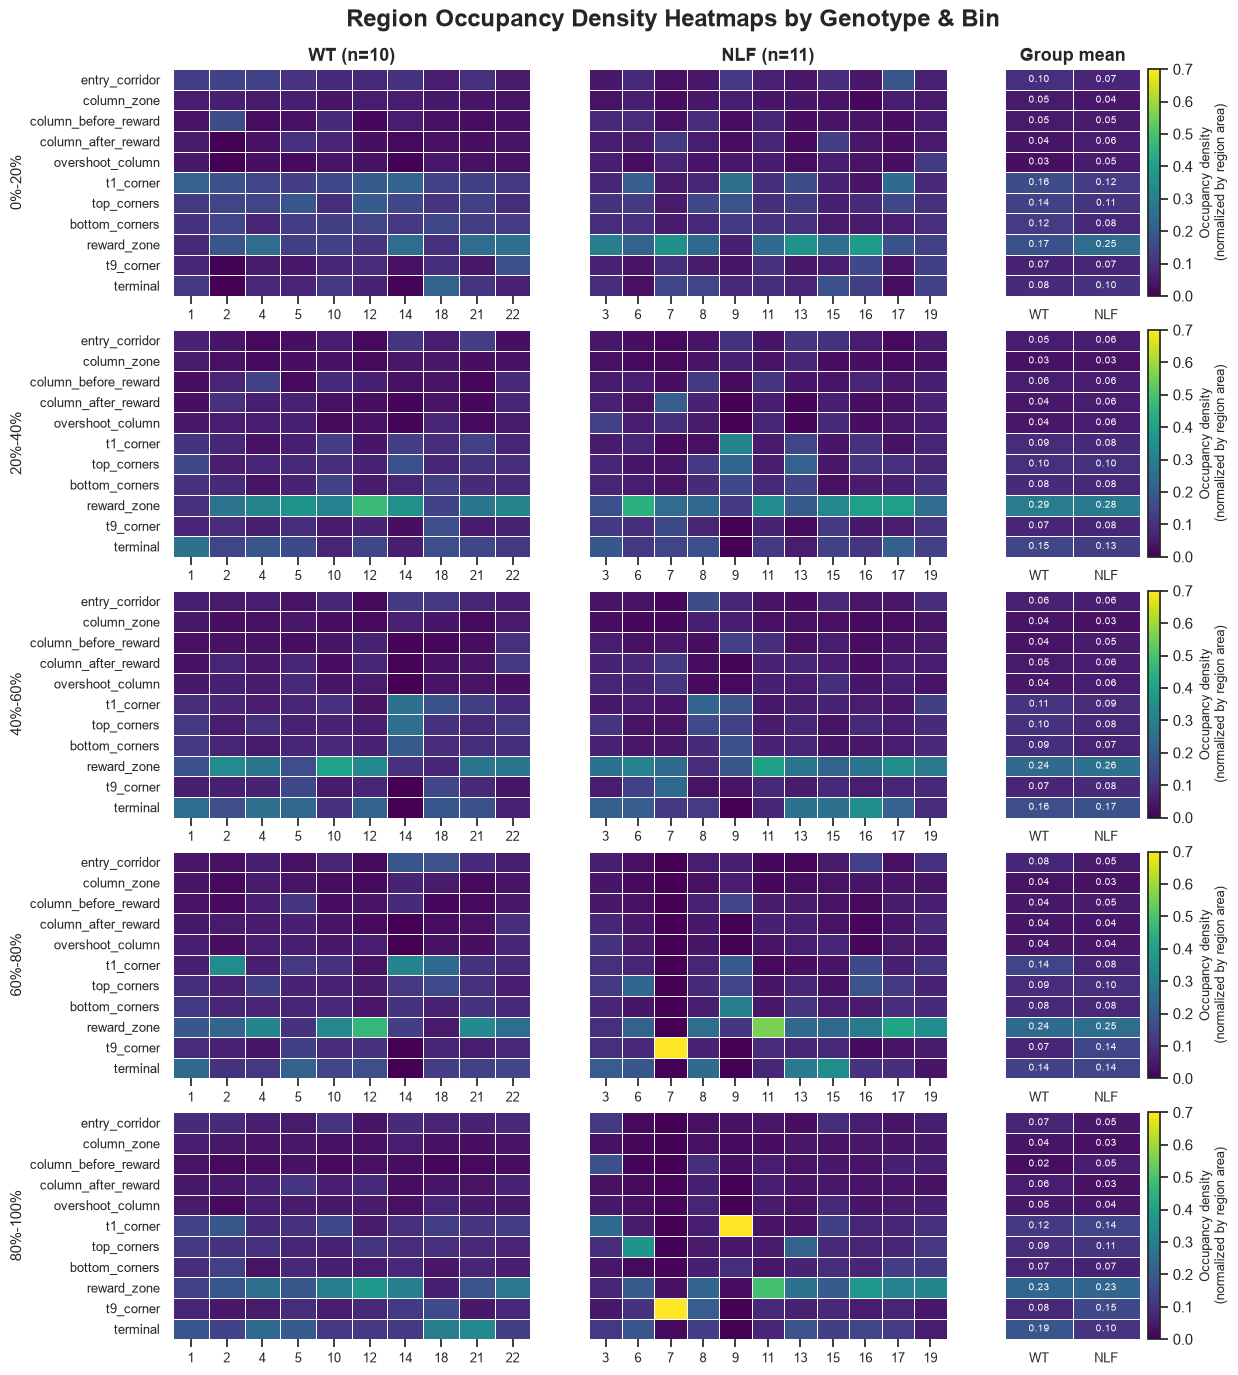

Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot1b_heatmap_pct\region_heatmaps_apoe_pair_except_entry_pct.pdf
Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot1b_heatmap_pct\region_heatmaps_all_except_entry_pct.pdf


In [9]:
from compass_labyrinth.behavior.behavior_metrics.task_performance_analysis import plot_region_heatmaps_all_genotypes


# Zone sets to plot (names from config.yaml zone_sets) -- add/remove names; one figure per comparison x set
ZONE_SET = ["except_entry"]
N_BINS = 5  # -> 20% segments
VMAX = 0.7  # max range on colorbar -- real data for original_4/wt_nlf reaches 1.0 (single-zone bins)

FIRST = (COMPARISONS[0], ZONE_SET[0])
for zone_set in ZONE_SET:
    ZONE_NAMES = ZONE_SETS[zone_set]
    for GENOTYPE_SET in COMPARISONS:
        df_geno = build_genotype_groups(df_all_csv, GENOTYPE_SET)
        pivot_dict_zones = build_zone_pivot_by_percentage(ZONE_NAMES, df=df_geno, n_bins=N_BINS)

        plot_region_heatmaps_all_genotypes(
            config=config,
            show_fig=(GENOTYPE_SET, zone_set) == FIRST,  # display only the first comparison x zone set; all are saved
            figures_dirname="figures/task_performance/plot1b_heatmap_pct",
            pivot_dict=pivot_dict_zones,
            df_all_csv=df_geno,
            lower_lim=0,
            upper_lim=100,
            difference=100 // N_BINS,
            bin_label_suffix="%",
            included_genotypes=list(GENOTYPE_SETS[GENOTYPE_SET].keys()),
            region_desired_order=ZONE_NAMES,
            spacing_w=0.2,
            spacing_h=0.15,
            show_colorbar=True,
            vmax=VMAX,
            filename_suffix=f"_{GENOTYPE_SET}_{zone_set}_pct",
        )

# Shannon's Entropy

This function calculates Shannon entropy over time, reflecting the diversity of region occupancy for each mouse/session within each time bin. A higher entropy indicates more distributed (less selective) region occupancy, whereas lower entropy suggests focused behavior within fewer regions.

### Recommended Use:
1. Ensure `pivot_dict` has been generated using `generate_region_heatmap_pivots()`.
2. Ensure `cohort_metadata` includes metadata 

In [10]:
from compass_labyrinth.behavior.behavior_metrics.task_performance_analysis import compute_shannon_entropy_per_bin


# Zone sets to plot (names from config.yaml zone_sets) -- add/remove names; one figure per comparison x set
ZONE_SET = ["5_columns", "10_rows"]

# Entropy is per session, so it doesn't depend on how genotypes are pooled:
# computed once per zone set on the raw genotypes, then relabeled for each
# comparison. Keyed (comparison, zone set).
entropy_by_comparison = {}
for zone_set in ZONE_SET:
    df_zones, pivot_dict_zones = build_zone_pivot(ZONE_SETS[zone_set], df=df_all_csv)
    entropy_df_raw = compute_shannon_entropy_per_bin(
        pivot_dict=pivot_dict_zones,
        df_all_csv=df_zones,
        bin_size=BIN_SIZE,
    )
    for gs in COMPARISONS:
        entropy_by_comparison[(gs, zone_set)] = build_genotype_groups(entropy_df_raw, gs)
FIRST = (COMPARISONS[0], ZONE_SET[0])
entropy_df_raw

,session,bin,entropy,genotype
0,1,5000,3.162453,E4
1,1,10000,3.087775,E4
2,1,15000,3.092281,E4
3,1,20000,3.151594,E4
4,1,25000,3.105992,E4
...,...,...,...,...
205,22,30000,NaN,E4
206,22,35000,NaN,E4
207,22,40000,NaN,E4
208,22,45000,NaN,E4


## Plot 2: Plotting Shannon's Entropy across Sessions (/Mice)

Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot2_entropy\shannon_entropy_wt_nlf_5_columns.pdf


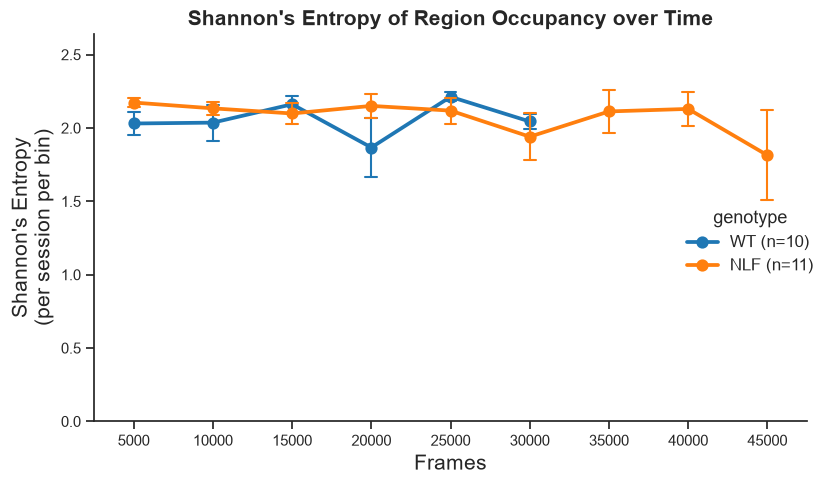

Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot2_entropy\shannon_entropy_apoe_pair_5_columns.pdf
Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot2_entropy\shannon_entropy_all_5_columns.pdf
Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot2_entropy\shannon_entropy_wt_nlf_10_rows.pdf
Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot2_entropy\shannon_entropy_apoe_pair_10_rows.pdf
Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot2_entropy\shannon_entropy_al

In [11]:
from compass_labyrinth.behavior.behavior_metrics.task_performance_analysis import plot_entropy_over_bins


# Plot entropy over time, one figure per comparison x zone set
for (GENOTYPE_SET, zone_set), entropy_df in entropy_by_comparison.items():
    plot_entropy_over_bins(
        config=config,
        show_fig=(GENOTYPE_SET, zone_set) == FIRST,  # display only the first comparison x zone set; all are saved
        figures_dirname="figures/task_performance/plot2_entropy",
        entropy_df=entropy_df,
        filename_suffix=f"_{GENOTYPE_SET}_{zone_set}",
    )

Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot2_entropy\shannon_entropy_zoomed_wt_nlf_5_columns.pdf


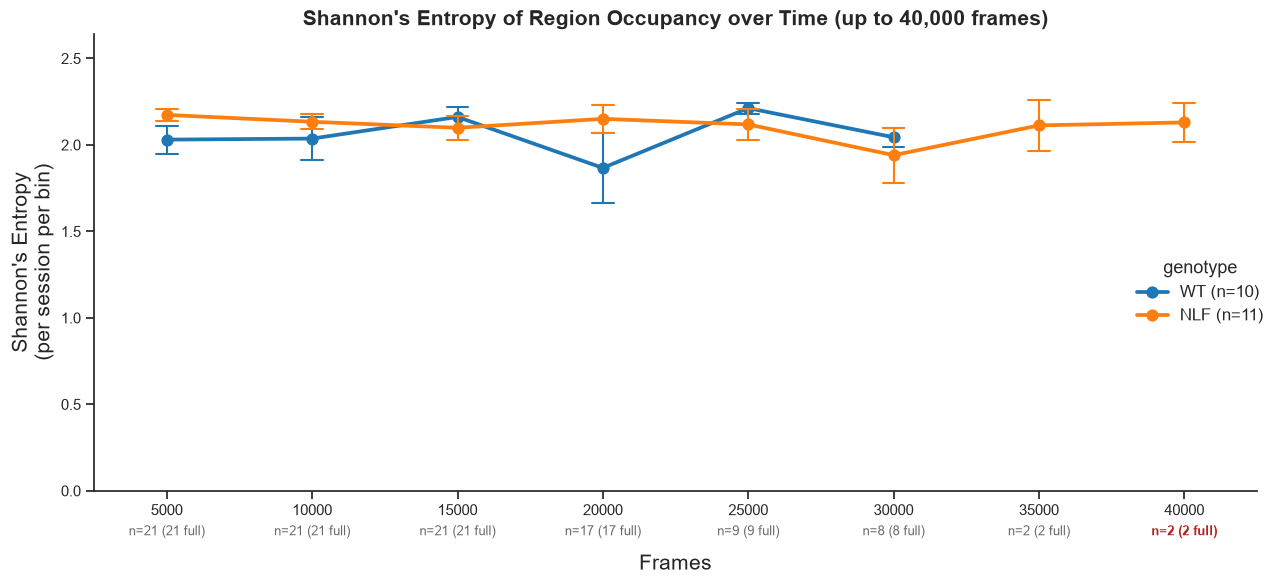

Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot2_entropy\shannon_entropy_zoomed_apoe_pair_5_columns.pdf
Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot2_entropy\shannon_entropy_zoomed_all_5_columns.pdf
Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot2_entropy\shannon_entropy_zoomed_wt_nlf_10_rows.pdf
Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot2_entropy\shannon_entropy_zoomed_apoe_pair_10_rows.pdf
Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot

In [12]:
from compass_labyrinth.behavior.behavior_metrics.task_performance_analysis import plot_entropy_over_bins_zoomed


# Zoomed-in view, cut off where sample size gets thin -- bin 40000 is the last
# bin with every genotype still represented; annotated below the x-axis
for (GENOTYPE_SET, zone_set), entropy_df in entropy_by_comparison.items():
    plot_entropy_over_bins_zoomed(
        config=config,
        show_fig=(GENOTYPE_SET, zone_set) == FIRST,  # display only the first comparison x zone set; all are saved
        figures_dirname="figures/task_performance/plot2_entropy",
        entropy_df=entropy_df,
        cutoff_bin=40000,
        df_all_csv=df_all_csv,
        filename_suffix=f"_{GENOTYPE_SET}_{zone_set}",
    )

### Statistical tests - Entropy

In [13]:
from compass_labyrinth.behavior.behavior_metrics.task_performance_analysis import (
    run_entropy_anova,
    run_fdr_pairwise_tests,
    run_mixed_model_per_genotype_pair,
)

## Need more than one genotype to run these
entropy_stats = {}
for (GENOTYPE_SET, zone_set), entropy_df in entropy_by_comparison.items():
    print(f"\n######## {GENOTYPE_SET} | {zone_set} ########")
    # Repeated Measures ANOVA
    anova_result = run_entropy_anova(entropy_df)

    # Pairwise t-tests + FDR correction (per bin, per genotype pair)
    fdr_results = run_fdr_pairwise_tests(entropy_df)
    print(fdr_results)

    # Per-pair mixed models; pairwise Bin x Genotype interaction summary
    mixed_results, interaction_table = run_mixed_model_per_genotype_pair(entropy_df)
    print(interaction_table)

    entropy_stats[(GENOTYPE_SET, zone_set)] = (anova_result, fdr_results, interaction_table)


######## wt_nlf | 5_columns ########
Repeated Measures ANOVA (within-subject Bin):
              Anova
    F Value Num DF  Den DF  Pr > F
----------------------------------
bin 44.8491 8.0000 160.0000 0.0000

     bin Group1 Group2    t-stat     raw-p     fdr_p  significant
0   5000     WT    NLF -1.641847  0.126615  0.390508        False
1  10000     WT    NLF -0.744917  0.471546  0.550642        False
2  15000     WT    NLF  0.690454  0.498346  0.550642        False
3  20000     WT    NLF -0.663693  0.515024  0.550642        False
4  25000     WT    NLF -1.030360  0.315820  0.550642        False
5  30000     WT    NLF -0.607635  0.550642  0.550642        False
6  35000     WT    NLF -1.486426  0.167999  0.390508        False
7  40000     WT    NLF -1.488134  0.167556  0.390508        False
8  45000     WT    NLF -1.465307  0.173559  0.390508        False

 MixedLM failed for WT vs NLF: Singular matrix
  genotype1 genotype2 interaction_pvals  significant
0        WT       NLF        

In [14]:
from pathlib import Path

# Save entropy stats alongside the other task-performance results, for the figure
# report -- tagged _<comparison>_<zone set> so it shows under the matching selection
stats_dir = Path(config["project_path_full"]) / "results" / "task_performance" / "plot2_entropy"
stats_dir.mkdir(parents=True, exist_ok=True)

for (GENOTYPE_SET, zone_set), (anova_result, fdr_results, interaction_table) in entropy_stats.items():
    suffix = f"_{GENOTYPE_SET}_{zone_set}"
    if anova_result is not None:
        anova_result.anova_table.to_csv(stats_dir / f"entropy_anova{suffix}.csv")
    fdr_results.to_csv(stats_dir / f"entropy_fdr_pairwise{suffix}.csv")
    interaction_table.to_csv(stats_dir / f"entropy_mixed_interaction{suffix}.csv")

## Plot 3: Proportion of usage across all Regions

Plot usage over time bins for all Regions:

Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot3_all_regions_usage\all_regions_prop_usage_wt_nlf_except_entry.pdf


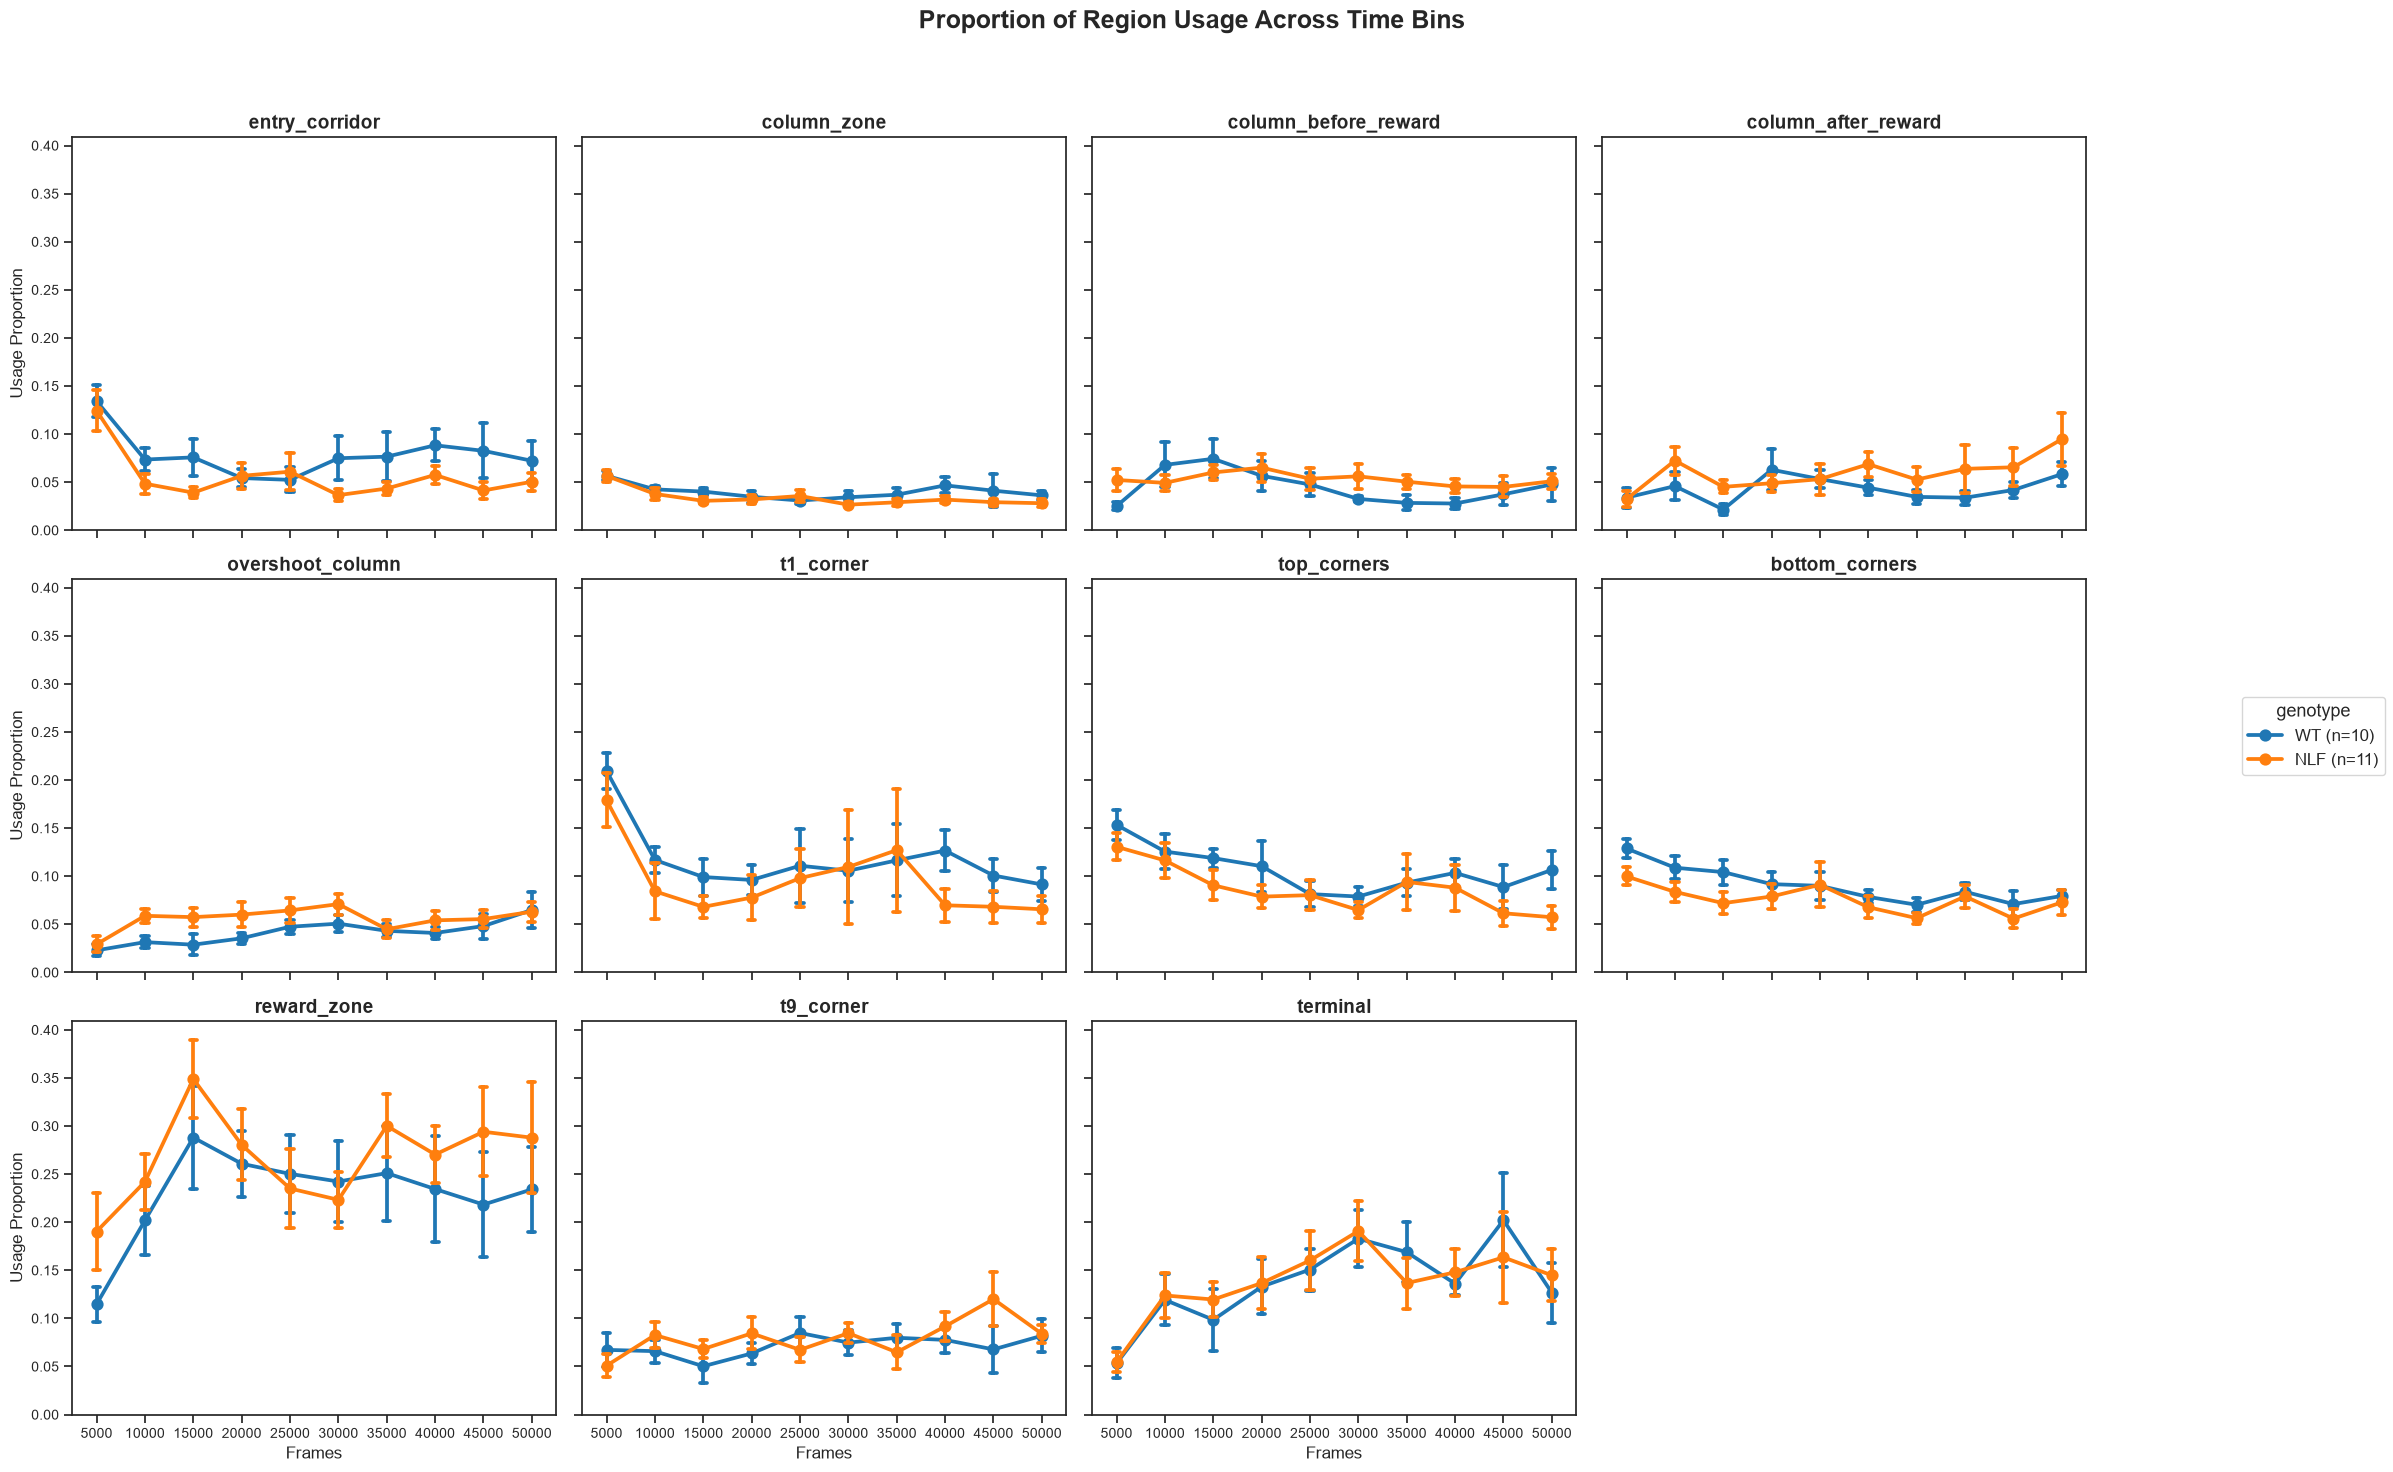

Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot3_all_regions_usage\all_regions_prop_usage_apoe_pair_except_entry.pdf
Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot3_all_regions_usage\all_regions_prop_usage_all_except_entry.pdf
Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot3_all_regions_usage\all_regions_prop_usage_wt_nlf_10_rows.pdf
Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot3_all_regions_usage\all_regions_prop_usage_apoe_pair_10_rows.pdf
Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\

In [15]:
from compass_labyrinth.behavior.behavior_metrics.task_performance_analysis import plot_all_regions_usage_over_bins

# Zone sets to plot (names from config.yaml zone_sets) -- add/remove names; one figure per comparison x set
ZONE_SET = ["except_entry", "10_rows", "around_reward_zones"]

YLIM = None          # y-axis range, e.g. (0, 0.4); None = start at 0 and fit the data (zone sets differ in typical share)
MAX_FRAMES = 50000  # cap the x-axis at this frame count (None = show every bin)

# Region usage is pooled per genotype group before binning, so it's rebuilt
# for each comparison x zone set. Kept for the stats cell below, keyed
# (comparison, zone set): the session -> genotype mapping and pivot_dict.
FIRST = (COMPARISONS[0], ZONE_SET[0])
region_usage_inputs = {}
for zone_set in ZONE_SET:
    ZONE_NAMES = ZONE_SETS[zone_set]
    for GENOTYPE_SET in COMPARISONS:
        df_geno = build_genotype_groups(df_all_csv, GENOTYPE_SET)
        df_zones, pivot_dict_zones = build_zone_pivot(ZONE_NAMES, df=df_geno)
        region_usage_inputs[(GENOTYPE_SET, zone_set)] = (df_zones[["session", "genotype"]].drop_duplicates(), pivot_dict_zones)

        plot_all_regions_usage_over_bins(
            config=config,
            show_fig=(GENOTYPE_SET, zone_set) == FIRST,  # display only the first comparison x zone set; all are saved
            figures_dirname="figures/task_performance/plot3_all_regions_usage",
            pivot_dict=pivot_dict_zones,
            df_all_csv=df_zones,
            region_list=ZONE_NAMES,
            bin_size=BIN_SIZE,
            ylim=YLIM,
            max_frames=MAX_FRAMES,
            filename_suffix=f"_{GENOTYPE_SET}_{zone_set}",
        )

### Statistical tests - region usage

In [16]:
from compass_labyrinth.behavior.behavior_metrics.task_performance_analysis import (
    compute_region_usage_over_bins,
    run_region_usage_stats_mixedlm,
    run_region_usage_stats_fdr,
)


# Per-zone stats for each comparison x zone set's "all regions" overlay above --
# the same pivot_dict/zone set/genotype grouping as its figure.
region_usage_stats = {}
for (GENOTYPE_SET, zone_set), (sessions_geno, pivot_dict_zones) in region_usage_inputs.items():
    print(f"\n######## {GENOTYPE_SET} | {zone_set} ########")
    fdr_by_zone = {}
    for zone in ZONE_SETS[zone_set]:
        reg_binned = compute_region_usage_over_bins(
            pivot_dict=pivot_dict_zones,
            df_all_csv=sessions_geno,
            region=zone,
            bin_size=BIN_SIZE,
        )
        print(f"\n=== {zone} ===")
        # Mixed Effects Model, then pairwise comparison across genotypes with FDR correction
        run_region_usage_stats_mixedlm(reg_binned, region_col=zone)
        fdr_by_zone[zone] = run_region_usage_stats_fdr(reg_binned, region_col=zone)
    region_usage_stats[(GENOTYPE_SET, zone_set)] = fdr_by_zone


######## wt_nlf | except_entry ########

=== entry_corridor ===

=== Mixed Effects Model (missing values preserved) ===
            Mixed Linear Model Regression Results
Model:             MixedLM Dependent Variable: entry_corridor
No. Observations:  258     Method:             REML          
No. Groups:        21      Scale:              0.0026        
Min. group size:   7       Log-Likelihood:     359.0783      
Max. group size:   28      Converged:          Yes           
Mean group size:   12.3                                      
-------------------------------------------------------------
                   Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------------
Intercept           0.068    0.009  7.487 0.000  0.050  0.086
genotype[T.WT]      0.010    0.014  0.718 0.473 -0.018  0.038
bin                -0.000    0.000 -2.124 0.034 -0.000 -0.000
bin:genotype[T.WT]  0.000    0.000  1.498 0.134 -0.000  0.000
Group Var           0.0

In [17]:
from pathlib import Path

# Save region-usage stats next to the Plot 3 figures, for the figure report.
# run_region_usage_stats_mixedlm() only prints its summary and returns None,
# so only the FDR-corrected pairwise results (one table per zone) are saved,
# tagged _<comparison>_<zone set>.
stats_dir = Path(config["project_path_full"]) / "results" / "task_performance" / "plot3_all_regions_usage"
stats_dir.mkdir(parents=True, exist_ok=True)

for (GENOTYPE_SET, zone_set), fdr_by_zone in region_usage_stats.items():
    for zone, fdr_results in fdr_by_zone.items():
        fdr_results.to_csv(stats_dir / f"region_usage_fdr_{zone}_{GENOTYPE_SET}_{zone_set}.csv")

## Plot 3b: Proportion of usage across all Regions, by Percentage of Session

Same as Plot 3, but built from a percentage-based `pivot_dict` (`build_zone_pivot_by_percentage()`) instead of a fixed-frame one -- see Plot 1b for why: every session contributes to every bin (first 20%, next 20%, ...) instead of short sessions dropping out of later bins.

Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot3b_all_regions_usage_pct\all_regions_prop_usage_wt_nlf_except_entry_pct.pdf


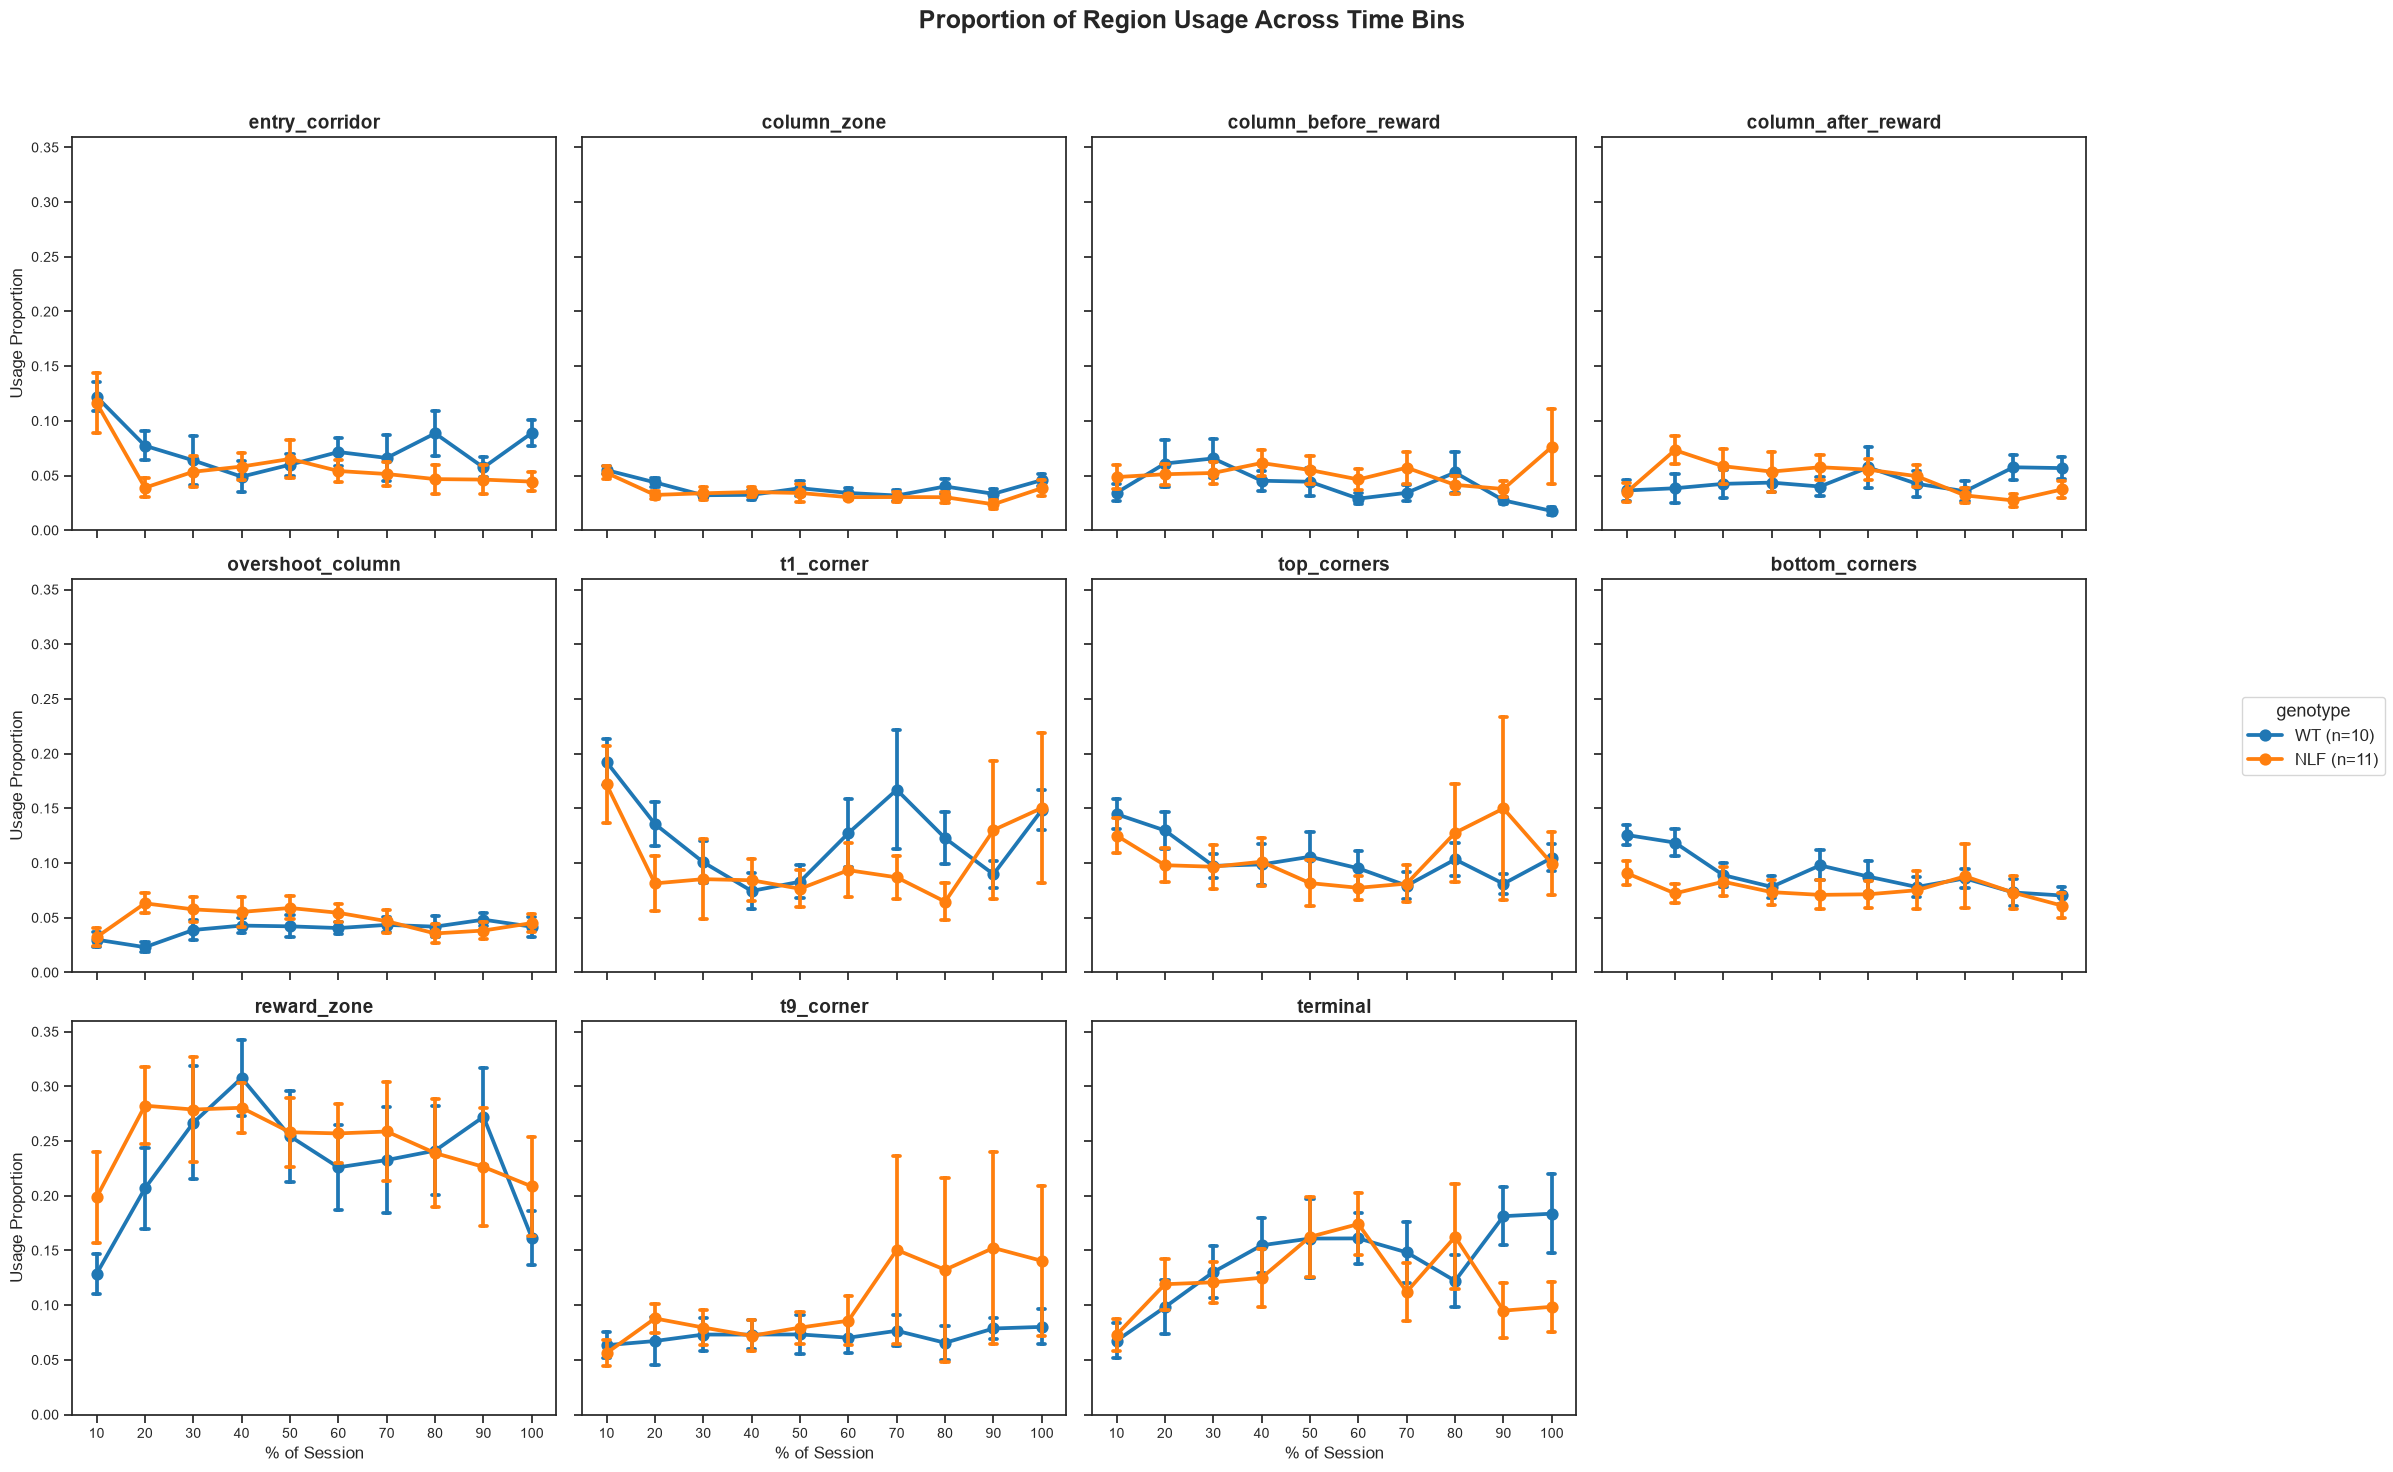

Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot3b_all_regions_usage_pct\all_regions_prop_usage_apoe_pair_except_entry_pct.pdf
Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot3b_all_regions_usage_pct\all_regions_prop_usage_all_except_entry_pct.pdf
Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot3b_all_regions_usage_pct\all_regions_prop_usage_wt_nlf_10_rows_pct.pdf
Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot3b_all_regions_usage_pct\all_regions_prop_usage_apoe_pair_10_rows_pct.pdf
Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 

In [18]:
from compass_labyrinth.behavior.behavior_metrics.task_performance_analysis import plot_all_regions_usage_over_bins

# Zone sets to plot (names from config.yaml zone_sets) -- add/remove names; one figure per comparison x set
ZONE_SET = ["except_entry", "10_rows", "around_reward_zones"]
N_BINS = 10  # -> 10% segments

YLIM = None  # y-axis range, e.g. (0, 0.4); None = start at 0 and fit the data

FIRST = (COMPARISONS[0], ZONE_SET[0])
for zone_set in ZONE_SET:
    ZONE_NAMES = ZONE_SETS[zone_set]
    for GENOTYPE_SET in COMPARISONS:
        df_geno = build_genotype_groups(df_all_csv, GENOTYPE_SET)
        pivot_dict_zones_pct = build_zone_pivot_by_percentage(ZONE_NAMES, df=df_geno, n_bins=N_BINS)

        plot_all_regions_usage_over_bins(
            config=config,
            show_fig=(GENOTYPE_SET, zone_set) == FIRST,  # display only the first comparison x zone set; all are saved
            figures_dirname="figures/task_performance/plot3b_all_regions_usage_pct",
            pivot_dict=pivot_dict_zones_pct,
            df_all_csv=df_geno,
            region_list=ZONE_NAMES,
            bin_size=100 // N_BINS,
            ylim=YLIM,
            xlabel="% of Session",
            filename_suffix=f"_{GENOTYPE_SET}_{zone_set}_pct",
        )

# Bout-Level Success Metrics

## Plot 4: Cumulative Successful Bout Percentage

A bout is defined as a continuous sequence starting from the Entry Zone, passing through non-entry nodes, and returning to the Entry Zone. 

A successful bout is defined as one in which the animal reaches the Target Zone at least once before returning to the Entry Zone.

Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot4_success_rate\cumulative_successful_bouts_wt_nlf.pdf


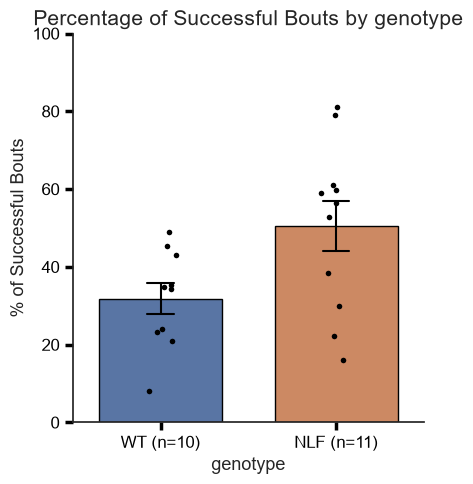

Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot4_success_rate\cumulative_successful_bouts_apoe_pair.pdf
Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot4_success_rate\cumulative_successful_bouts_all.pdf


In [19]:
from compass_labyrinth.behavior.behavior_metrics.task_performance_analysis import (
    assign_bout_indices_from_entry_zone,
    summarize_bout_success_by_session,
    plot_success_rate,
)
from compass_labyrinth.constants import ENTRY_ZONE


# 1. Assign bout indices -- once, on the raw genotypes (bouts are per session).
# entry_zone is [0, 1] (grown from just [0] -- see constants.py), so
# delimiter_nodes=ENTRY_ZONE catches sessions that never happen to have
# tracked data in cell 0 exactly but do in its neighbor cell 1
df_all_csv_wbouts = assign_bout_indices_from_entry_zone(df_all_csv, delimiter_nodes=ENTRY_ZONE)

# 2. Success summary per session, relabeled for each genotype comparison
bout_summary_raw = summarize_bout_success_by_session(df_all_csv_wbouts)
bout_summary_by_comparison = {gs: build_genotype_groups(bout_summary_raw, gs) for gs in COMPARISONS}

# 3. Plot % of successful bouts per genotype group, one figure per comparison
for GENOTYPE_SET, bout_summary in bout_summary_by_comparison.items():
    plot_success_rate(
        config=config,
        show_fig=GENOTYPE_SET == COMPARISONS[0],  # display the first comparison only; all are saved
        figures_dirname="figures/task_performance/plot4_success_rate",
        summary_table=bout_summary,
        filename_suffix=f"_{GENOTYPE_SET}",
    )

### Statistical tests - genotypes

Perform t-test on Success Rate:

In [20]:
from compass_labyrinth.behavior.behavior_metrics.task_performance_analysis import perform_genotype_ttests


ttest_results_by_comparison = {}
for GENOTYPE_SET, bout_summary in bout_summary_by_comparison.items():
    ttest_results_success = perform_genotype_ttests(bout_summary, rate_col='success_rate')
    ttest_results_by_comparison[GENOTYPE_SET] = ttest_results_success
    print(f"T-Test on Success Rate ({GENOTYPE_SET}):")
    for k, v in ttest_results_success.items():
        print(f"  {k}: t={v['t_stat']:.3f}, p={v['p_value']:.4f}, mean1={v['mean_1']:.2f}, mean2={v['mean_2']:.2f}")

T-Test on Success Rate (wt_nlf):
  WT vs NLF: t=-2.460, p=0.0253, mean1=31.82, mean2=50.54
T-Test on Success Rate (apoe_pair):
  APOE4 vs APOE3: t=0.962, p=0.3481, mean1=45.60, mean2=37.25
T-Test on Success Rate (all):
  E4 vs E3NLF: t=-1.408, p=0.2463, mean1=36.87, mean2=50.45
  E4 vs E3: t=1.256, p=0.2558, mean1=36.87, mean2=28.45
  E4 vs E4NLF: t=-1.457, p=0.1911, mean1=36.87, mean2=50.59
  E3NLF vs E3: t=1.934, p=0.1041, mean1=50.45, mean2=28.45
  E3NLF vs E4NLF: t=-0.010, p=0.9920, mean1=50.45, mean2=50.59
  E3 vs E4NLF: t=-1.980, p=0.0750, mean1=28.45, mean2=50.59


In [21]:
import pandas as pd
from pathlib import Path

# Save success-rate t-tests alongside the other task-performance results, for
# the figure report -- tagged _<comparison> so each shows under its selection
stats_dir = Path(config["project_path_full"]) / "results" / "task_performance" / "plot4_success_rate"
stats_dir.mkdir(parents=True, exist_ok=True)

for GENOTYPE_SET, ttest_results_success in ttest_results_by_comparison.items():
    pd.DataFrame.from_dict(ttest_results_success, orient="index").to_csv(
        stats_dir / f"success_rate_ttests_{GENOTYPE_SET}.csv"
    )

## Plot 5: Time-based Successful Bout Percentage

This function computes the percentage of successful bouts within sequential time bins across all sessions, allowing time-resolved assessment of goal-directed behavior.

### Recommended Use:
1. Ensure `df_all_csv` includes 'Session', 'Grid.Number', 'Bout_Index', and time-ordered rows.
2. Set `lower_succ_lim` and `upper_succ_lim` to define the full range of timepoints to analyze.
3. Set `diff_succ` as the size of each time bin (e.g., 5000).
4. Use `valid_bout_threshold` to exclude short bouts (e.g., < 19 steps).
5. Set `optimal_path_regions` to define which regions are required for optimal navigation.
6. Set `target_zone` to specify the region that marks a successful bout.

In [22]:
from compass_labyrinth.behavior.behavior_metrics.task_performance_analysis import (
    assign_bout_indices_from_entry_zone,
    compute_binned_success_summary,
)
from compass_labyrinth.constants import ENTRY_ZONE


# Set these values
BIN_SIZE = 5000
LOWER_BOUND = 0
UPPER_BOUND = 90000

# Per-session binned success -- computed once on the raw genotypes, relabeled per comparison
df_all_csv_wbouts_plot5 = assign_bout_indices_from_entry_zone(df_all_csv, delimiter_nodes=ENTRY_ZONE)

summary_df_raw = compute_binned_success_summary(
    df_all_csv=df_all_csv_wbouts_plot5,
    lower_succ_lim=LOWER_BOUND,
    upper_succ_lim=UPPER_BOUND,
    diff_succ=BIN_SIZE,
    valid_bout_threshold=19,
    optimal_path_regions=['entry_zone', 'reward_path', 'target_zone'],
    target_zone='target_zone'
)
summary_by_comparison = {gs: build_genotype_groups(summary_df_raw, gs) for gs in COMPARISONS}
summary_df_raw

,session,genotype,bout_num,no_of_bouts,no_valid_bouts,no_of_succ_bouts,no_of_perfect_bouts,succ_bout_perc
0,1,E4,5000,18,13,2,0,15.384615
1,1,E4,10000,17,15,3,0,20.000000
2,1,E4,15000,11,11,3,0,27.272727
3,1,E4,20000,10,10,5,0,50.000000
4,1,E4,25000,10,8,3,0,37.500000
...,...,...,...,...,...,...,...,...
362,22,E4,15000,8,7,3,0,42.857143
363,22,E4,20000,8,8,4,0,50.000000
364,22,E4,25000,9,9,2,0,22.222222
365,22,E4,30000,8,8,4,0,50.000000


Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot5_time_based_success\time_based_successful_bouts_wt_nlf.pdf


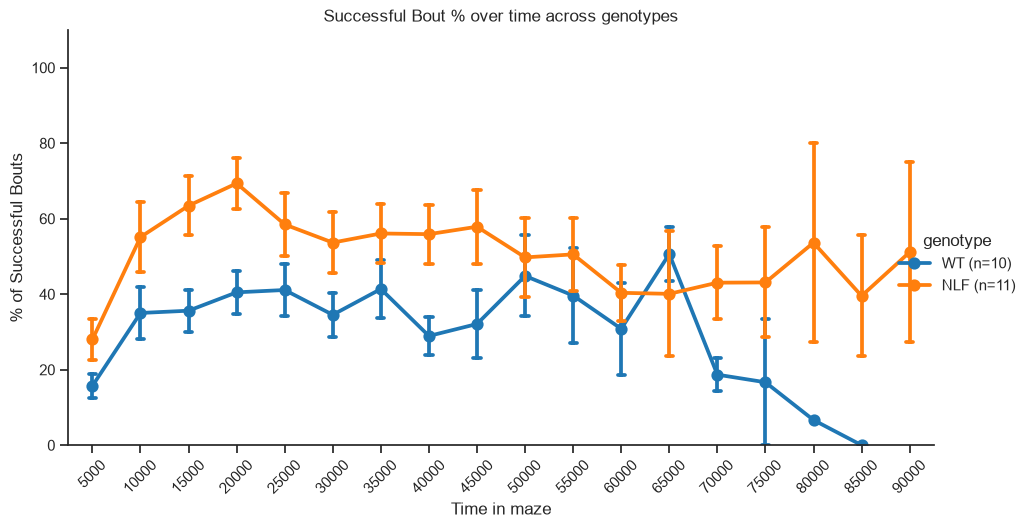

Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot5_time_based_success\time_based_successful_bouts_apoe_pair.pdf
Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot5_time_based_success\time_based_successful_bouts_all.pdf


In [23]:
from compass_labyrinth.behavior.behavior_metrics.task_performance_analysis import plot_binned_success


# Visualize the percentage of successful bouts within each time bin, one figure per comparison
for GENOTYPE_SET, summary_df in summary_by_comparison.items():
    plot_binned_success(
        config=config,
        show_fig=GENOTYPE_SET == COMPARISONS[0],  # display the first comparison only; all are saved
        figures_dirname="figures/task_performance/plot5_time_based_success",
        summary_df=summary_df,
        filename_suffix=f"_{GENOTYPE_SET}",
    )

## Plot 5b: Time-based Successful Bout Percentage, by Percentage of Session

Same as Plot 5, but bins each session by percentage of its own total frame count (first 20%, next 20%, ...) instead of a fixed absolute frame range -- same idea as Plot 1b/3b: every session contributes to every bin, comparing "first 20% of the session" for one mouse against "first 20%" for another, regardless of how many raw frames that took.

### Recommended Use:
1. Ensure `df_all_csv` includes 'Session', 'Grid.Number', 'Bout_Index', and time-ordered rows.
2. Set `N_BINS` (default 5 -> 20% segments).
3. Use `valid_bout_threshold` to exclude short bouts (e.g., < 19 steps).
4. Set `optimal_path_regions` to define which regions are required for optimal navigation.
5. Set `target_zone` to specify the region that marks a successful bout.

In [24]:
from compass_labyrinth.behavior.behavior_metrics.task_performance_analysis import (
    assign_bout_indices_from_entry_zone,
    compute_binned_success_summary_by_percentage,
)
from compass_labyrinth.constants import ENTRY_ZONE


# Set these values
N_BINS = 10  # -> 10% segments

# Per-session binned success -- computed once on the raw genotypes, relabeled per comparison
df_all_csv_wbouts_plot5b = assign_bout_indices_from_entry_zone(df_all_csv, delimiter_nodes=ENTRY_ZONE)

summary_df_pct_raw = compute_binned_success_summary_by_percentage(
    df_all_csv=df_all_csv_wbouts_plot5b,
    n_bins=N_BINS,
    valid_bout_threshold=19,
    optimal_path_regions=['entry_zone', 'reward_path', 'target_zone'],
    target_zone='target_zone'
)
summary_pct_by_comparison = {gs: build_genotype_groups(summary_df_pct_raw, gs) for gs in COMPARISONS}
summary_df_pct_raw

,session,genotype,bout_num,no_of_bouts,no_valid_bouts,no_of_succ_bouts,no_of_perfect_bouts,succ_bout_perc
0,1,E4,10,14,9,2,0,22.222222
1,1,E4,20,18,16,3,0,18.750000
2,1,E4,30,10,10,3,0,30.000000
3,1,E4,40,7,7,3,0,42.857143
4,1,E4,50,9,9,4,0,44.444444
...,...,...,...,...,...,...,...,...
205,22,E4,60,6,6,2,0,33.333333
206,22,E4,70,3,3,1,0,33.333333
207,22,E4,80,9,8,1,0,12.500000
208,22,E4,90,7,7,3,0,42.857143


Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot5b_time_based_success_pct\time_based_successful_bouts_wt_nlf_pct.pdf


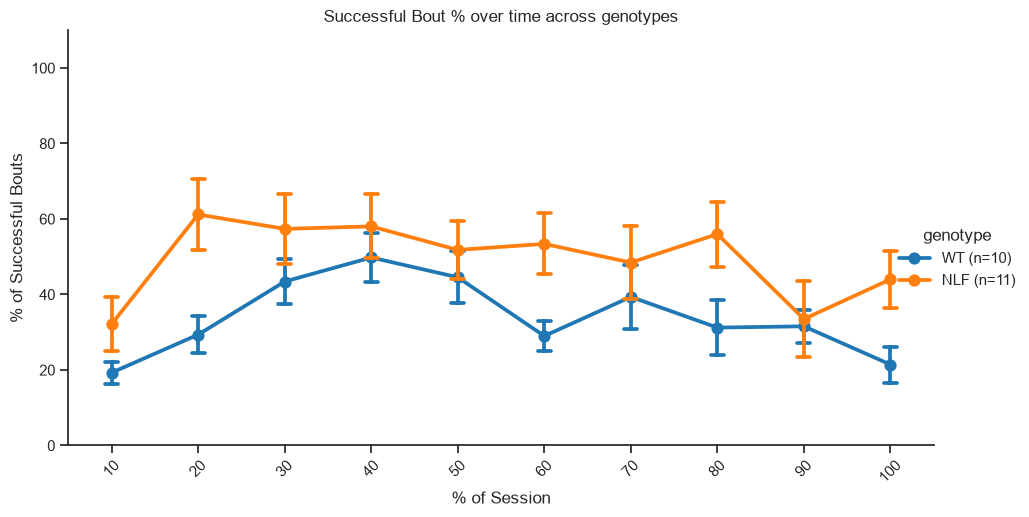

Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot5b_time_based_success_pct\time_based_successful_bouts_apoe_pair_pct.pdf
Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot5b_time_based_success_pct\time_based_successful_bouts_all_pct.pdf


In [25]:
from compass_labyrinth.behavior.behavior_metrics.task_performance_analysis import plot_binned_success


# Visualize the percentage of successful bouts within each percentage-of-session bin, per comparison
for GENOTYPE_SET, summary_df_pct in summary_pct_by_comparison.items():
    plot_binned_success(
        config=config,
        show_fig=GENOTYPE_SET == COMPARISONS[0],  # display the first comparison only; all are saved
        figures_dirname="figures/task_performance/plot5b_time_based_success_pct",
        summary_df=summary_df_pct,
        xlabel="% of Session",
        filename_suffix=f"_{GENOTYPE_SET}_pct",
    )

### Statistical tests - time-based

In [26]:
from compass_labyrinth.behavior.behavior_metrics.task_performance_analysis import (
    run_mixedlm_with_nans,
    run_repeated_measures_anova,
    run_pairwise_comparisons,
)


for GENOTYPE_SET, summary_df in summary_by_comparison.items():
    print(f"\n######## {GENOTYPE_SET} ########")
    # Run Mixed Linear Model (preserves NaNs)
    #run_mixedlm_with_nans(summary_df)

    # Run Repeated Measures ANOVA (NaNs filled with 0)
    run_repeated_measures_anova(summary_df)

    # Run Pairwise Comparisons (with FDR correction)
    run_pairwise_comparisons(summary_df)


######## wt_nlf ########

Running Repeated Measures ANOVA (NaNs filled with 0)...
ANOVA failed: Between subject effect not yet supported!

Running Pairwise Comparisons with Tukey HSD + FDR...
   group1 group2  meandiff   p-adj     lower     upper  reject  bout_num  \
0     NLF     WT  -12.2837  0.0759  -25.9767    1.4092   False      5000   
1     NLF     WT  -20.1026  0.1025  -44.6265    4.4212   False     10000   
2     NLF     WT  -27.8168  0.0108  -48.4325   -7.2011    True     15000   
3     NLF     WT  -28.8687  0.0046  -47.6793  -10.0581    True     20000   
4     NLF     WT  -17.3581  0.1262  -40.0715    5.3552   False     25000   
5     NLF     WT  -19.1278  0.0731  -40.2330    1.9774   False     30000   
6     NLF     WT  -14.7049  0.1995  -37.8560    8.4463   False     35000   
7     NLF     WT  -26.9707  0.0104  -46.6842   -7.2571    True     40000   
8     NLF     WT  -25.7617  0.0747  -54.4297    2.9063   False     45000   
9     NLF     WT   -4.9053  0.7483  -37.2311   

# Plot 6: Zone Occupancy and Velocity

This function computes, per bout, the occupancy fraction of each zone in a chosen `ZONE_SET` (instead of a single overshoot/deviation fraction), normalizes and smooths each zone's occupancy plus velocity, and fits exponential curves to the processed data -- one line per zone. Pass `zone_names=["overshoot"]` to reproduce the original single-line "deviation" view exactly.

### Recommended Use:
1. Pick a `GENOTYPE_SET` and a `ZONE_SET` from `ZONE_SETS` (any number of zones -- one line per zone).
2. Use `compute_zone_occupancy_velocity()` + `process_zone_occupancy_velocity()` to get per-genotype fits.
3. Use `plot_zone_occupancy_velocity_fit()` to visualize the trajectory of zone occupancy per genotype.

In [27]:
from compass_labyrinth.behavior.behavior_metrics.task_performance_analysis import (
    ensure_velocity_column,
    ensure_bout_indices,
    compute_zone_occupancy_velocity,
)
from compass_labyrinth.constants import ENTRY_ZONE


# Zone sets to plot (names from config.yaml zone_sets) -- add/remove names; one figure per comparison x set
ZONE_SET = ["reward_zones", "around_reward_zones"]
N_BINS = 400  # resolution for binning bout number before averaging/smoothing
# Y-axis limits for every Plot 6 figure below (this cell's downstream cells) --
# real zone-occupancy fractions are often well under 1.0, so narrow this
# (e.g. (0, 0.1)) to use the plot area better and see more line/CI detail.
OCCUPANCY_YLIM = (0, 0.5)

# Velocity, bouts and per-bout zone occupancy are all per session -- computed
# once on the raw genotypes; each comparison's figure relabels the result.
# (A copy, so the velocity column isn't added to df_all_csv itself.)
df_all_csv_wvelocity = ensure_velocity_column(
    df=df_all_csv.copy(),
    frame_rate=5.0,
)

# Ensure Bout Index column Bout_ID exists
df_all_csv_wbouts = ensure_bout_indices(
    df=df_all_csv_wvelocity,
    delimiter_node=ENTRY_ZONE,
)

# Per-zone occupancy and velocity per bout, one table per zone set -- one
# line per zone instead of a single overshoot/deviation fraction
df_occupancy = {
    zone_set: compute_zone_occupancy_velocity(df_all_csv_wbouts, zones=ZONES, zone_names=ZONE_SETS[zone_set])
    for zone_set in ZONE_SET
}
PLOT6_ZONE_SET = ZONE_SET  # the cells below reuse Plot 6's zone sets
FIRST = (COMPARISONS[0], ZONE_SET[0])

### Zone Occupancy and Velocity for all Genotypes

Plot Zone Occupancy-Velocity plots for all genotypes

Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot6_zone_occupancy_velocity\all_genotypes_zone_occupancy_velocity_metric_wt_nlf_reward_zones.pdf


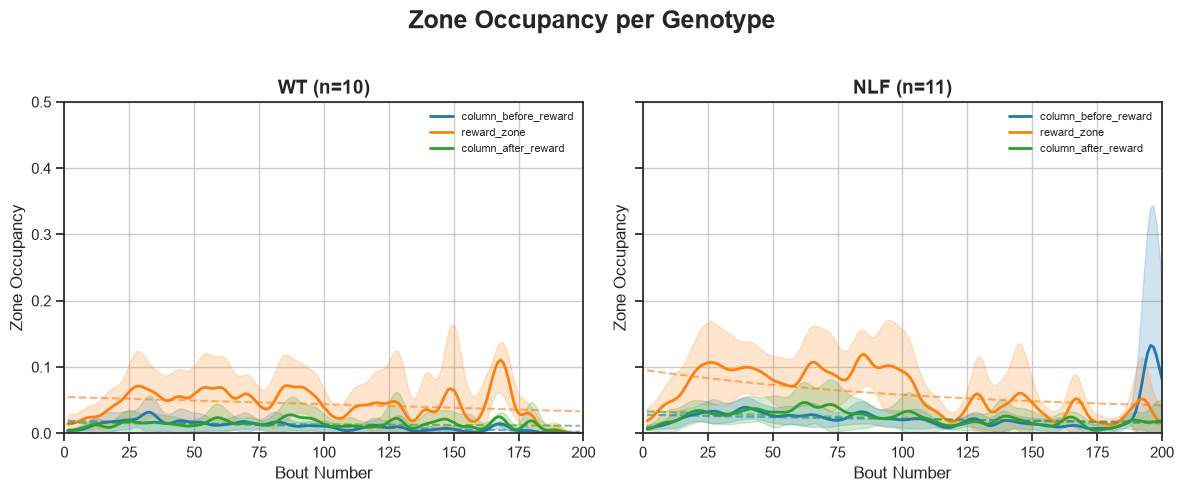

Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot6_zone_occupancy_velocity\all_genotypes_zone_occupancy_velocity_metric_apoe_pair_reward_zones.pdf
Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot6_zone_occupancy_velocity\all_genotypes_zone_occupancy_velocity_metric_all_reward_zones.pdf
Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot6_zone_occupancy_velocity\all_genotypes_zone_occupancy_velocity_metric_wt_nlf_around_reward_zones.pdf
Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot6_zone_occupancy_velocity\all_genotypes_zone_occupancy_velocity_metric_apoe_pair

In [28]:
from compass_labyrinth.behavior.behavior_metrics.task_performance_analysis import plot_zone_occupancy_velocity_all


for zone_set in PLOT6_ZONE_SET:
    for GENOTYPE_SET in COMPARISONS:
        plot_zone_occupancy_velocity_all(
            config=config,
            show_fig=(GENOTYPE_SET, zone_set) == FIRST,  # display only the first comparison x zone set; all are saved
            figures_dirname="figures/task_performance/plot6_zone_occupancy_velocity",
            index_df=build_genotype_groups(df_occupancy[zone_set], GENOTYPE_SET),
            zone_names=ZONE_SETS[zone_set],
            max_bouts=200,
            n_bins=N_BINS,
            show_velocity=False,
            genotype_order=list(GENOTYPE_SETS[GENOTYPE_SET].keys()),
            ylim=OCCUPANCY_YLIM,
            filename_suffix=f"_{GENOTYPE_SET}_{zone_set}",
        )

### Zone Occupancy and Velocity per Genotype (Successful Bouts Only)

Unsuccessful bouts (never reaching target_zone) can't reach overshoot either -- they mechanically contribute occupancy=0 for overshoot-adjacent zones, which dilutes the real signal rather than reflecting it. Restricting to bouts that reached target_zone at least once isolates the genuine behavior.

Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot6_zone_occupancy_velocity\all_genotypes_zone_occupancy_velocity_metric_wt_nlf_reward_zones_successful_only.pdf


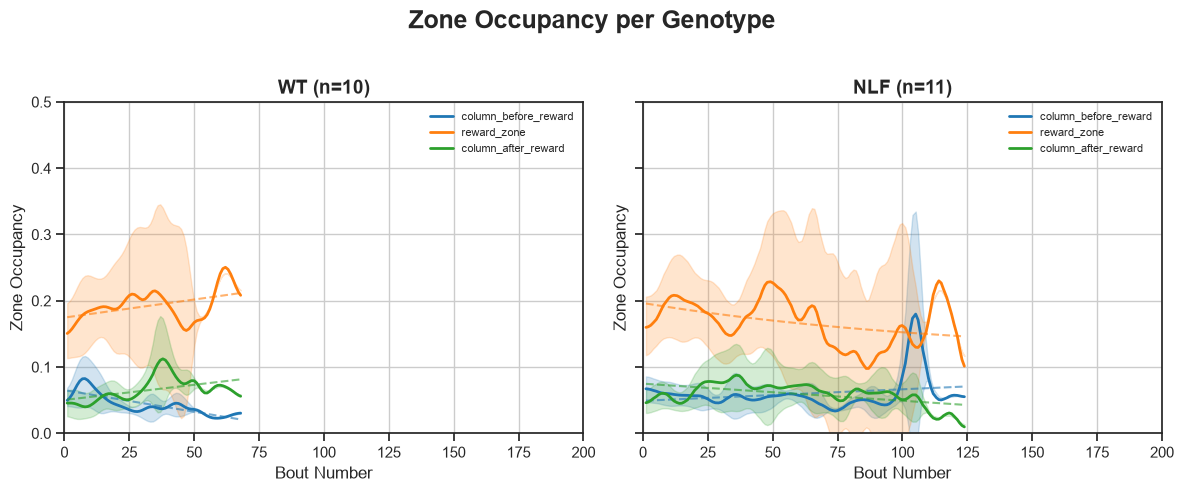

Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot6_zone_occupancy_velocity\all_genotypes_zone_occupancy_velocity_metric_apoe_pair_reward_zones_successful_only.pdf
Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot6_zone_occupancy_velocity\all_genotypes_zone_occupancy_velocity_metric_all_reward_zones_successful_only.pdf
Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot6_zone_occupancy_velocity\all_genotypes_zone_occupancy_velocity_metric_wt_nlf_around_reward_zones_successful_only.pdf
Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot6_zone_occupancy_velocity\all_ge

In [29]:
from compass_labyrinth.behavior.behavior_metrics.task_performance_analysis import (
    compute_zone_occupancy_velocity,
    plot_zone_occupancy_velocity_all,
)


# Restrict to bouts that actually reached the target zone (once per zone set, raw genotypes)
df_occupancy_successful = {
    zone_set: compute_zone_occupancy_velocity(
        df_all_csv_wbouts, zones=ZONES, zone_names=ZONE_SETS[zone_set], successful_only=True
    )
    for zone_set in PLOT6_ZONE_SET
}

for zone_set in PLOT6_ZONE_SET:
    for GENOTYPE_SET in COMPARISONS:
        plot_zone_occupancy_velocity_all(
            config=config,
            show_fig=(GENOTYPE_SET, zone_set) == FIRST,  # display only the first comparison x zone set; all are saved
            figures_dirname="figures/task_performance/plot6_zone_occupancy_velocity",
            index_df=build_genotype_groups(df_occupancy_successful[zone_set], GENOTYPE_SET),
            zone_names=ZONE_SETS[zone_set],
            max_bouts=200,
            n_bins=N_BINS,
            show_velocity=False,
            genotype_order=list(GENOTYPE_SETS[GENOTYPE_SET].keys()),
            ylim=OCCUPANCY_YLIM,
            filename_suffix=f"_{GENOTYPE_SET}_{zone_set}_successful_only",
        )

# Plot 6b: Zone Occupancy and Velocity, by Percentage of Bouts

Same as Plot 6 (per-zone occupancy fractions + velocity), but each bout's position is expressed as a percentage of that session's own total bout count (0-100%) instead of a raw sequential bout number. Sessions vary a lot in how many bouts a mouse attempts; comparing "bout 50" across a mouse with 60 total bouts and one with 300 total bouts means very different things, while "80% through this mouse's own bouts" is directly comparable across mice.

### Recommended Use:
1. Pick a `GENOTYPE_SET` and a `ZONE_SET` from `ZONE_SETS` (any number of zones -- one line per zone).
2. Use `compute_zone_occupancy_velocity_by_percentage()` + `process_zone_occupancy_velocity()` to get per-genotype fits.
3. Use `plot_zone_occupancy_velocity_all()` to visualize every genotype at once (the per-genotype `plot_zone_occupancy_velocity_fit()` figures were dropped here -- the all-genotypes view already covers the same data).

In [30]:
from compass_labyrinth.behavior.behavior_metrics.task_performance_analysis import compute_zone_occupancy_velocity_by_percentage


# Zone sets to plot (names from config.yaml zone_sets) -- add/remove names; one figure per comparison x set
ZONE_SET = ["reward_zones", "around_reward_zones"]
N_BINS = 200  # resolution for binning % of bouts before averaging/smoothing
# Y-axis limits for every Plot 6b figure below (this cell's downstream cells) --
# real zone-occupancy fractions are often well under 1.0, so narrow this
# (e.g. (0, 0.1)) to use the plot area better and see more line/CI detail.
OCCUPANCY_YLIM_PCT = (0, 0.4)

# Reuses Plot 6's velocity + bout indices (df_all_csv_wbouts) -- the same data;
# only the bout position changes, to % of that session's own total bout count
# (0-100%) instead of a raw bout number. Raw genotypes, relabeled per comparison.
df_occupancy_pct = {
    zone_set: compute_zone_occupancy_velocity_by_percentage(df_all_csv_wbouts, zones=ZONES, zone_names=ZONE_SETS[zone_set])
    for zone_set in ZONE_SET
}
PLOT6B_ZONE_SET = ZONE_SET  # the cells below reuse Plot 6b's zone sets
FIRST = (COMPARISONS[0], ZONE_SET[0])

### Zone Occupancy and Velocity for all Genotypes (% of Bouts)

Plot Zone Occupancy-Velocity plots for all genotypes

Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot6b_zone_occupancy_velocity_pct\all_genotypes_zone_occupancy_velocity_metric_wt_nlf_reward_zones_pct.pdf


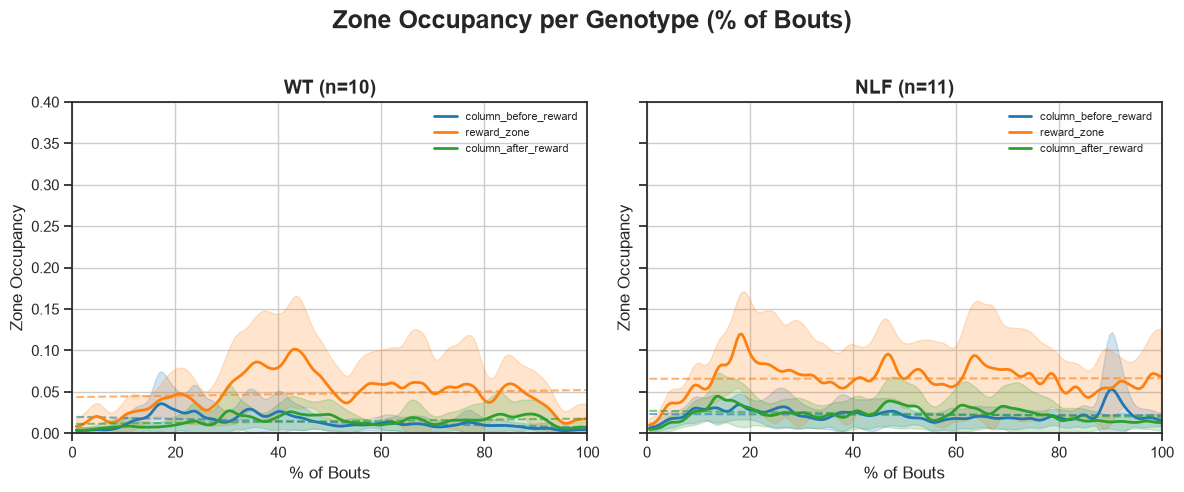

Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot6b_zone_occupancy_velocity_pct\all_genotypes_zone_occupancy_velocity_metric_apoe_pair_reward_zones_pct.pdf
Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot6b_zone_occupancy_velocity_pct\all_genotypes_zone_occupancy_velocity_metric_all_reward_zones_pct.pdf
Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot6b_zone_occupancy_velocity_pct\all_genotypes_zone_occupancy_velocity_metric_wt_nlf_around_reward_zones_pct.pdf
Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot6b_zone_occupancy_velocity_pct\all_genotypes_zone_occ

In [31]:
from compass_labyrinth.behavior.behavior_metrics.task_performance_analysis import plot_zone_occupancy_velocity_all


for zone_set in PLOT6B_ZONE_SET:
    for GENOTYPE_SET in COMPARISONS:
        plot_zone_occupancy_velocity_all(
            config=config,
            show_fig=(GENOTYPE_SET, zone_set) == FIRST,  # display only the first comparison x zone set; all are saved
            figures_dirname="figures/task_performance/plot6b_zone_occupancy_velocity_pct",
            index_df=build_genotype_groups(df_occupancy_pct[zone_set], GENOTYPE_SET),
            zone_names=ZONE_SETS[zone_set],
            max_bouts=100,
            n_bins=N_BINS,
            xlabel="% of Bouts",
            title_suffix=" (% of Bouts)",
            show_velocity=False,
            genotype_order=list(GENOTYPE_SETS[GENOTYPE_SET].keys()),
            ylim=OCCUPANCY_YLIM_PCT,
            filename_suffix=f"_{GENOTYPE_SET}_{zone_set}_pct",
        )

### Zone Occupancy and Velocity per Genotype (Successful Bouts Only, % of Bouts)

Unsuccessful bouts (never reaching target_zone) can't reach overshoot either -- they mechanically contribute occupancy=0 for overshoot-adjacent zones, which dilutes the real signal rather than reflecting it. Restricting to bouts that reached target_zone at least once isolates the genuine behavior (see Plot 6's version of this cell for the exact same rationale).

Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot6b_zone_occupancy_velocity_pct\all_genotypes_zone_occupancy_velocity_metric_wt_nlf_reward_zones_pct_successful_only.pdf


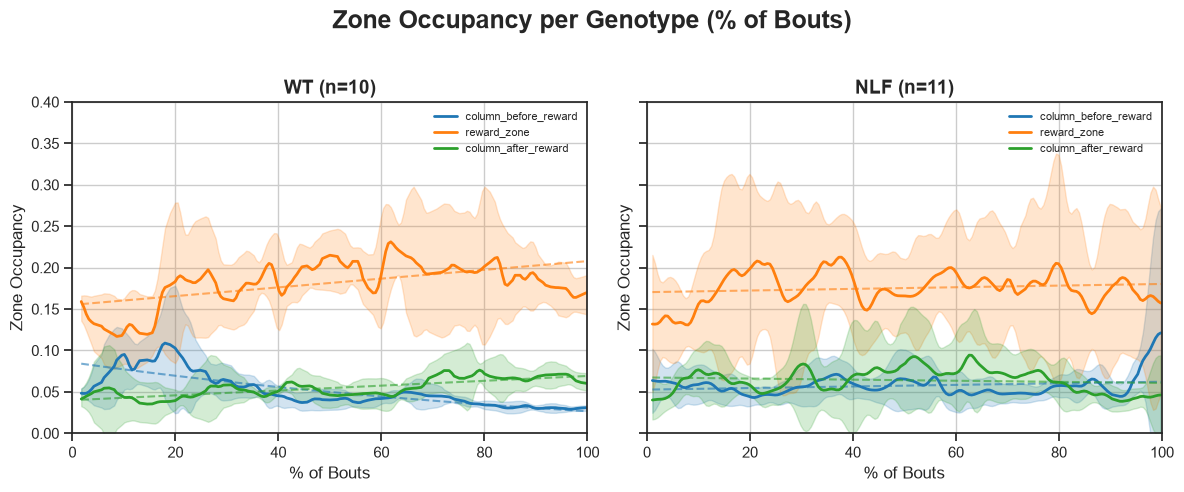

Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot6b_zone_occupancy_velocity_pct\all_genotypes_zone_occupancy_velocity_metric_apoe_pair_reward_zones_pct_successful_only.pdf
Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot6b_zone_occupancy_velocity_pct\all_genotypes_zone_occupancy_velocity_metric_all_reward_zones_pct_successful_only.pdf
Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot6b_zone_occupancy_velocity_pct\all_genotypes_zone_occupancy_velocity_metric_wt_nlf_around_reward_zones_pct_successful_only.pdf
Figure saved at: D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\figures\task_performance\plot6b_zo

In [32]:
from compass_labyrinth.behavior.behavior_metrics.task_performance_analysis import (
    compute_zone_occupancy_velocity_by_percentage,
    plot_zone_occupancy_velocity_all,
)


# Restrict to bouts that actually reached the target zone (once per zone set, raw genotypes)
df_occupancy_pct_successful = {
    zone_set: compute_zone_occupancy_velocity_by_percentage(
        df_all_csv_wbouts, zones=ZONES, zone_names=ZONE_SETS[zone_set], successful_only=True
    )
    for zone_set in PLOT6B_ZONE_SET
}

for zone_set in PLOT6B_ZONE_SET:
    for GENOTYPE_SET in COMPARISONS:
        plot_zone_occupancy_velocity_all(
            config=config,
            show_fig=(GENOTYPE_SET, zone_set) == FIRST,  # display only the first comparison x zone set; all are saved
            figures_dirname="figures/task_performance/plot6b_zone_occupancy_velocity_pct",
            index_df=build_genotype_groups(df_occupancy_pct_successful[zone_set], GENOTYPE_SET),
            zone_names=ZONE_SETS[zone_set],
            max_bouts=100,
            n_bins=N_BINS,
            xlabel="% of Bouts",
            title_suffix=" (% of Bouts)",
            show_velocity=False,
            genotype_order=list(GENOTYPE_SETS[GENOTYPE_SET].keys()),
            ylim=OCCUPANCY_YLIM_PCT,
            filename_suffix=f"_{GENOTYPE_SET}_{zone_set}_pct_successful_only",
        )

# Write the Data Sheet

Writes every table recorded by the plotting functions above (both raw and binned/aggregated -- whatever each figure was actually drawn from) into one Excel workbook, with mouse metadata joined on.

In [33]:
source_data.keep("mice", source_data.metadata())
sheets = source_data.find("")
readme = {name: ("", "") for name in sheets}
source_data.write_workbook(
    str(Path(config["project_path_full"]) / "results" / "task_performance" / f"{config['project_name']}_task_performance_datasheet.xlsx"),
    sheets,
    readme,
)

saved datasheet D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\results\task_performance\New_Reward_E3E4NLF_task_performance_datasheet.xlsx


['D:\\Gladstone Dropbox\\Palop Lab\\Nina\\Experiments\\For Level 1 CoMPASS States\\New_Reward_E3E4NLF\\compass_analysis\\results\\task_performance\\New_Reward_E3E4NLF_task_performance_datasheet.xlsx']

# Rebuild the Figure Report

Regenerates `analysis_report.html` from whatever figures/stats are currently on disk for BOTH pipelines (task performance and level 1) -- run this notebook last if you want the report to reflect it.

In [34]:
from compass_labyrinth.report import build_report

build_report(config["project_path_full"])

Wrote D:\Gladstone Dropbox\Palop Lab\Nina\Experiments\For Level 1 CoMPASS States\New_Reward_E3E4NLF\compass_analysis\analysis_report.html (287 figures, 24 significant rows)


WindowsPath('D:/Gladstone Dropbox/Palop Lab/Nina/Experiments/For Level 1 CoMPASS States/New_Reward_E3E4NLF/compass_analysis/analysis_report.html')